In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import seaborn as sns
from datetime import datetime
import warnings
import kagglehub
from scipy import stats

## 1. Project Overview

Hypothesis Summary: Weather and Tourist Arrivals in Singapore

**Research question:** To what extent do weather conditions in Singapore explain changes in tourist arrivals, and how can the Singapore Tourism Board (STB) use this analysis to increase tourism?

### Hypotheses

| | Statement |
|---|---|
| **H₀ (null)** | Weather conditions (rainfall, rainy days, temperature, sunshine, humidity) have **no significant effect** on monthly tourist arrivals to Singapore. |
| **H₁ (working hypothesis)** | Weather conditions, such as the monsoon seasons, **significantly influence** monthly tourist arrival volumes. |

**Type of Analysis**: This project will utilize Time-Series Regression Analysis. While Singapore possesses a relatively static tropical climate year-round, granular weather data (e.g., monthly rainfall, humidity, and temperature variations) exhibits certain level of variance to impact travel decisions. By analyzing historical weather and arrival data, we aim to build a model that predicts arrival peaks and troughs.

**Targeted Quality Metric**: The performance of our predictive model will be evaluated using Mean Absolute Error (MAE) to understand the average deviation in our predicted visitor counts, alongside R-squared ($R^2$) to determine the proportion of variance in tourist arrivals that can be explained by our weather variables.

### Data Used
- SingStat monthly weather data (rainfall, rainy days, max temperature, sunshine hours, humidity) 
- SingStat monthly tourist arrivals, 2008–2025
- The Kaggle Global Weather Repository, used as secondary source to validate the SingStat monthly weather data.



## 2.Data Source Identification and EDA


*   **Singapore Weather Data**
*   [Global Weather Repository (DS1)](https://www.kaggle.com/datasets/nelgiriyewithana/global-weather-repository/data/discussion)
*   [Singapore Air Temperature, Sunshine, Relative Humidity and Rainfall in Singapore (DS2)](https://tablebuilder.singstat.gov.sg/table/TS/M890081)
*   **Singapore Tourism Data**
*   [Singapore Tourist Arrival (DS3)](https://tablebuilder.singstat.gov.sg/table/TS/M550001)

In [ ]:
import kagglehub
import glob
import os
import pandas as pd
import numpy as np

def find_repo_root(start=os.getcwd()):
    current = os.path.abspath(start)
    while True:
        if os.path.isdir(os.path.join(current, ".git")):
            return current
        parent = os.path.dirname(current)
        if parent == current:          # reached the drive root without finding .git
            return os.path.abspath(start)
        current = parent

REPO_ROOT = find_repo_root()
DATA_DIR = os.path.join(REPO_ROOT, "data")
os.makedirs(DATA_DIR, exist_ok=True)

# Pin a specific dataset version so the data can be replicated
KAGGLE_DATASET = "nelgiriyewithana/global-weather-repository/versions/1105"

# Only download from Kaggle if the CSV is not already in the repository's data folder
csv_files = glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
if not csv_files:
    print("Downloading dataset from Kaggle into:", DATA_DIR)
    kagglehub.dataset_download(
        KAGGLE_DATASET,
        output_dir=DATA_DIR,       # save straight into the repo instead of the kagglehub cache
        force_download=True,
    )
    csv_files = glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)

if not csv_files:
    raise FileNotFoundError(f"No CSV found in {DATA_DIR} after downloading. Check your internet connection / Kaggle login.")

print("Path to dataset files:", DATA_DIR)

# Load the CSV from the repository's data folder
file_path = csv_files[0]
print("Loading:", file_path)
df = pd.read_csv(file_path)
print(df.shape)

Path to dataset files: c:\Users\wenju\Data-Processing\data
Loading: c:\Users\wenju\Data-Processing\data\GlobalWeatherRepository.csv


(170733, 41)


##### 2.3.1.1 Data Profiling for Source 1

In [3]:
# Data is loaded from Kaggle in the cell above (df)
country_col = df.columns[0]

#We only want data for Singapore
singapore_data = df[df[country_col].astype(str).str.strip() == 'Singapore']
singapore_data.to_csv('singapore_only.csv', index=False)

print("Data Profiling for Source 1: Global Weather Repository")
print("="*60)

df = singapore_data  # your existing Source 1 dataframe

print("\n1. STRUCTURE INSPECTION")
print("-" * 60)
print(f"Source 1 has {df.shape[0]} rows and {df.shape[1]} columns")

print("\n2. DATA TYPES & MISSING VALUES")
print("-" * 60)
print("\nColumn Data Types:")
print(df.dtypes)
print("\nMissing Values:")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({
    'Missing Count': missing,
    'Percentage': missing_pct
})
print(missing_summary[missing_summary['Missing Count'] > 0])

print("\n3. STATISTICAL PROFILING (Numeric Columns)")
print("-" * 60)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"\nNumeric columns found: {len(numeric_cols)}")
print(numeric_cols[:10])
if len(numeric_cols) > 0:
    print("\nSummary Statistics:")
    print(df[numeric_cols].describe())

print("\n4. CATEGORICAL COLUMNS ANALYSIS")
print("-" * 60)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"\nCategorical columns found: {len(categorical_cols)}")
for col in categorical_cols[:5]:
    print(f"\n'{col}' - Unique values: {df[col].nunique()}")
    if df[col].nunique() <= 20:
        print(df[col].value_counts())
    else:
        print(f"Top 10 values:")
        print(df[col].value_counts().head(10))

print("\n5. DATE/DATETIME ANALYSIS")
print("-" * 60)
date_cols = df.select_dtypes(include=['datetime64']).columns.tolist()
for col in df.columns:
    if 'date' in col.lower() or 'time' in col.lower():
        if col not in date_cols:
            try:
                df[col + '_converted'] = pd.to_datetime(df[col], errors='coerce')
                if df[col + '_converted'].notna().sum() > len(df) * 0.5:
                    date_cols.append(col)
                    print(f"Found potential date column: '{col}'")
            except:
                pass
if len(date_cols) > 0:
    for col in date_cols:
        if col in df.columns:
            print(f"\n'{col}':")
            try:
                date_range = df[col].max() - df[col].min()
                print(f"  Date range: {df[col].min()} to {df[col].max()}")
                if hasattr(date_range, 'days'):
                    print(f"  Total days: {date_range.days}")
            except:
                print(f"  Range: {df[col].min()} to {df[col].max()}")
else:
    print("No date columns detected.")

print("\n6. DATA QUALITY CHECKS")
print("-" * 60)
duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates}")
if len(numeric_cols) > 0:
    print("\nZero values in numeric columns:")
    for col in numeric_cols[:10]:
        zero_count = (df[col] == 0).sum()
        if zero_count > 0:
            print(f"  {col}: {zero_count} zeros ({zero_count/len(df)*100:.2f}%)")

print("\n7. CORRELATION ANALYSIS (Top Numeric Columns)")
print("-" * 60)
if len(numeric_cols) >= 2:
    corr_cols = numeric_cols[:min(10, len(numeric_cols))]
    corr_matrix = df[corr_cols].corr()
    strong_corr = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            corr_val = corr_matrix.iloc[i, j]
            if abs(corr_val) > 0.7:
                strong_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_val))
    if strong_corr:
        print("\nStrong correlations found (|r| > 0.7):")
        for col1, col2, val in strong_corr[:10]:
            print(f"  {col1} <-> {col2}: {val:.3f}")
    else:
        print("No strong correlations found (|r| > 0.7)")
else:
    print("Insufficient numeric columns for correlation analysis.")

print("\n8. UNIQUE IDENTIFIERS CHECK")
print("-" * 60)
for col in df.columns[:10]:
    unique_ratio = df[col].nunique() / len(df)
    if unique_ratio == 1.0:
        print(f"'{col}' - Potential unique identifier (100% unique)")
    elif unique_ratio > 0.95:
        print(f"'{col}' - High uniqueness ({unique_ratio*100:.1f}%)")

print("\n9. DATA QUALITY DISCUSSION (Balanced Evaluation)")
print("-" * 60)

overall_missing_pct = (df.isnull().sum().sum() / (df.shape[0] * df.shape[1])) * 100

print("\nCompleteness:")
if overall_missing_pct < 5:
    print(f"  (+) The dataset is highly complete with only {overall_missing_pct:.2f}% missing values, reducing the need for extensive data cleaning.")
else:
    print(f"  (-) The dataset has {overall_missing_pct:.2f}% missing values, which may require imputation or removal of incomplete records during preprocessing.")

print("\nReliability:")
print(f"  (-) Data is downloaded from \"Kaggle.\" and hence might not be as reliable as those other data from governmental sources. Cross referencing is required.")

print("\nTimeliness:")
if len(date_cols) > 0:
    try:
        # Convert Unix timestamp to datetime
        min_ts = df[date_cols[0]].min()
        max_ts = df[date_cols[0]].max()

        min_date = pd.to_datetime(min_ts, unit='s')
        max_date = pd.to_datetime(max_ts, unit='s')

        print(f"  (+) The dataset is updated daily from {min_date} to {max_date}, allowing for temporal analysis.")
    except:
        print("  (-) Date columns exist but could not be converted properly.")
else:
    print("  (-) No date information available.")


Data Profiling for Source 1: Global Weather Repository

1. STRUCTURE INSPECTION
------------------------------------------------------------
Source 1 has 877 rows and 41 columns

2. DATA TYPES & MISSING VALUES
------------------------------------------------------------

Column Data Types:
country                             str
location_name                       str
latitude                        float64
longitude                       float64
timezone                            str
last_updated_epoch                int64
last_updated                        str
temperature_celsius             float64
temperature_fahrenheit          float64
condition_text                      str
wind_mph                        float64
wind_kph                        float64
wind_degree                       int64
wind_direction                      str
pressure_mb                     float64
pressure_in                     float64
precip_mm                       float64
precip_in                    

C:\Users\wenju\AppData\Local\Temp\ipykernel_35692\2113753674.py:41: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns.tolist()


##### 2.3.1.2 Data Structuring for Source 1

In [4]:
print("Data Structuring for Source 1: Global Weather Repository")
print("="*60)

# Filter to Singapore only
df_s1 = df[df['country'].str.lower() == 'singapore'].copy()
print(f"\nRows after Singapore filter: {len(df_s1)}")

# Parse datetime column
df_s1['last_updated'] = pd.to_datetime(df_s1['last_updated'], errors='coerce')
invalid_dates = df_s1['last_updated'].isna().sum()
print(f"Invalid datetime entries removed: {invalid_dates}")
df_s1 = df_s1[df_s1['last_updated'].notna()].copy()

# Extract month period for aggregation
df_s1['month'] = df_s1['last_updated'].dt.to_period('M')

# Keep only relevant columns for analysis
s1_keep = ['month', 'temperature_celsius', 'humidity', 'precip_mm']
df_s1 = df_s1[s1_keep].copy()

# Standardise column names
df_s1.rename(columns={
    'temperature_celsius' : 'temp_celsius',
    'humidity'            : 'humidity_pct',
    'precip_mm'           : 'rainfall_mm'
}, inplace=True)

print(f"\nColumns retained : {df_s1.columns.tolist()}")
print(f"Shape            : {df_s1.shape}")
print(f"Date range       : {df_s1['month'].min()} to {df_s1['month'].max()}")
print("\nFirst 5 rows:")
print(df_s1.head())

Data Structuring for Source 1: Global Weather Repository

Rows after Singapore filter: 877
Invalid datetime entries removed: 0

Columns retained : ['month', 'temp_celsius', 'humidity_pct', 'rainfall_mm']
Shape            : (877, 4)
Date range       : 2024-05 to 2026-10

First 5 rows:
       month  temp_celsius  humidity_pct  rainfall_mm
156  2024-05          26.0            89         1.75
351  2024-05          27.0            94         0.00
545  2024-05          28.0            89         0.52
737  2024-05          29.0            75         0.00
932  2024-05          29.0            79         0.35


##### 2.3.1.3 Data Enriching for Source 1

In [5]:
print("Data Enriching for Source 1: Global Weather Repository")
print("="*60)

# Aggregate daily readings to monthly, since Source 2 and 3 are both in monthly granaluarity
print("\nAggregating daily to monthly...")
df_s1_monthly = df_s1.groupby('month').agg(
    temp_celsius = ('temp_celsius', 'mean'),
    humidity_pct = ('humidity_pct', 'mean'),
    rainfall_mm  = ('rainfall_mm',  'sum')   # total monthly rainfall
).reset_index()

# Derive month number and year
df_s1_monthly['year']      = df_s1_monthly['month'].dt.year
df_s1_monthly['month_num'] = df_s1_monthly['month'].dt.month

# Add Singapore meteorological season
def get_season(m):
    if m in [12, 1, 2]:        return 'Northeast Monsoon'
    elif m in [3, 4]:           return 'Inter-monsoon 1'
    elif m in [5, 6, 7, 8, 9]: return 'Southwest Monsoon'
    else:                       return 'Inter-monsoon 2'

df_s1_monthly['season'] = df_s1_monthly['month_num'].apply(get_season)

# 3-month rolling averages for key variables
df_s1_monthly['temp_3m_avg']     = df_s1_monthly['temp_celsius'].rolling(window=3, min_periods=1).mean().round(2)
df_s1_monthly['humidity_3m_avg'] = df_s1_monthly['humidity_pct'].rolling(window=3, min_periods=1).mean().round(2)
df_s1_monthly['rainfall_3m_avg'] = df_s1_monthly['rainfall_mm'].rolling(window=3, min_periods=1).mean().round(2)

print(f"Shape after aggregation : {df_s1_monthly.shape}")
print(f"New columns added       : year, month_num, season, temp_3m_avg, humidity_3m_avg, rainfall_3m_avg")
print("\nFirst 5 rows:")
print(df_s1_monthly.head())

Data Enriching for Source 1: Global Weather Repository

Aggregating daily to monthly...
Shape after aggregation : (30, 10)
New columns added       : year, month_num, season, temp_3m_avg, humidity_3m_avg, rainfall_3m_avg

First 5 rows:
     month  temp_celsius  humidity_pct  rainfall_mm  year  month_num  \
0  2024-05     28.294118     83.529412         7.36  2024          5   
1  2024-06     28.360000     78.366667         6.65  2024          6   
2  2024-07     28.896552     74.551724         1.29  2024          7   
3  2024-08     28.809677     73.000000         0.52  2024          8   
4  2024-09     29.693333     68.433333        11.28  2024          9   

              season  temp_3m_avg  humidity_3m_avg  rainfall_3m_avg  
0  Southwest Monsoon        28.29            83.53             7.36  
1  Southwest Monsoon        28.33            80.95             7.00  
2  Southwest Monsoon        28.52            78.82             5.10  
3  Southwest Monsoon        28.69            75.31  

##### 2.3.1.4 Data Cleaning for Source 1

In [6]:
print("Data Cleaning for Source 1: Global Weather Repository")
print("="*60)

# Remove duplicate months
before = len(df_s1_monthly)
df_s1_monthly = df_s1_monthly.drop_duplicates(subset='month').sort_values('month').reset_index(drop=True)
print(f"\nDuplicate months removed : {before - len(df_s1_monthly)}")

# Validate realistic ranges for Singapore weather
print("\nApplying range validation...")
invalid_temp     = (~df_s1_monthly['temp_celsius'].between(20, 40)).sum()
invalid_humidity = (~df_s1_monthly['humidity_pct'].between(0, 100)).sum()
invalid_rainfall = (df_s1_monthly['rainfall_mm'] < 0).sum()

df_s1_monthly.loc[~df_s1_monthly['temp_celsius'].between(20, 40),  'temp_celsius'] = np.nan
df_s1_monthly.loc[~df_s1_monthly['humidity_pct'].between(0, 100),  'humidity_pct'] = np.nan
df_s1_monthly.loc[df_s1_monthly['rainfall_mm'] < 0,                'rainfall_mm']  = np.nan

print(f"  temp_celsius  : {invalid_temp} out-of-range values replaced with NaN")
print(f"  humidity_pct  : {invalid_humidity} out-of-range values replaced with NaN")
print(f"  rainfall_mm   : {invalid_rainfall} negative values replaced with NaN")

# Interpolate missing values (if there even is any)
print("\nInterpolating missing values...")
df_s1_monthly[['temp_celsius', 'humidity_pct', 'rainfall_mm']] = (
    df_s1_monthly[['temp_celsius', 'humidity_pct', 'rainfall_mm']]
    .interpolate(method='linear', limit_direction='both')
)

print(f"Remaining nulls : {df_s1_monthly.isnull().sum().sum()}")
print(f"Final shape     : {df_s1_monthly.shape}")
print("\nFirst 5 rows:")
print(df_s1_monthly.head())

Data Cleaning for Source 1: Global Weather Repository

Duplicate months removed : 0

Applying range validation...
  temp_celsius  : 0 out-of-range values replaced with NaN
  humidity_pct  : 0 out-of-range values replaced with NaN
  rainfall_mm   : 0 negative values replaced with NaN

Interpolating missing values...
Remaining nulls : 0
Final shape     : (30, 10)

First 5 rows:
     month  temp_celsius  humidity_pct  rainfall_mm  year  month_num  \
0  2024-05     28.294118     83.529412         7.36  2024          5   
1  2024-06     28.360000     78.366667         6.65  2024          6   
2  2024-07     28.896552     74.551724         1.29  2024          7   
3  2024-08     28.809677     73.000000         0.52  2024          8   
4  2024-09     29.693333     68.433333        11.28  2024          9   

              season  temp_3m_avg  humidity_3m_avg  rainfall_3m_avg  
0  Southwest Monsoon        28.29            83.53             7.36  
1  Southwest Monsoon        28.33            80.

##### 2.3.1.5 Potential areas to conduct further analysis

1. **Time Series Analysis:** Examine trends over the 622-day period
2. **Correlation Studies:** Investigate relationships between variables (e.g., temperature vs. humidity)
3. **Seasonal Decomposition:** Identify cyclical patterns
4. **Extreme Event Prediction:** Model conditions leading to heavy rain or high UV
5. **Air Quality Modeling:** Analyze factors contributing to PM2.5 spikes
6. **Comparison:** Compare with historical Singapore climate data






#### 2.3.2 Dataset 2 (DS2): Singapore Air Temperature, Sunshine, Relative Humidity, and Rainfall in Singapore

Descripton: This dataset is sourced from the National Environment Agency (NEA) via Singapore's Department of Statistics (SingStat Table Builder M890081), provides comprehensive monthly meteorological data for Singapore. The dataset includes 10 weather variables across temperature metrics (daily maximum/minimum means and absolute extremes), precipitation measures (total rainfall, highest daily rainfall, and number of rainy days), and environmental conditions (daily sunshine hours and relative humidity).

##### 2.3.2.1 Data Profiling for Source 2

In [ ]:
import json
import urllib.request

SINGSTAT_API = 'https://tablebuilder.singstat.gov.sg/api/table/tabledata/'

def load_singstat_table(table_id, page_size=5000):
    series = {}  # seriesNo -> {'label': ..., 'values': {month: value}}
    offset = 0
    while True:
        url = f"{SINGSTAT_API}{table_id}?offset={offset}&limit={page_size}"
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0', 'Accept': 'application/json'})
        with urllib.request.urlopen(req, timeout=60) as resp:
            payload = json.load(resp)
        if payload.get('StatusCode') != 200:
            raise RuntimeError(f"SingStat API error for {table_id}: {payload.get('Message')}")
        rows = payload['Data'].get('row') or []
        n_points = sum(len(r['columns']) for r in rows)
        for r in rows:
            entry = series.setdefault(r['seriesNo'], {'row': r, 'values': {}})
            entry['values'].update({c['key']: c['value'] for c in r['columns']})
        if n_points < page_size:
            break
        offset += page_size

    # Units in brackets only when the series do not all share one unit (as in the export)
    units = {e['row']['uoM'] for e in series.values()}
    records = []
    for no, e in series.items():
        r = e['row']
        label = '  ' * (no.count('.')) + r['rowText']
        if len(units) > 1:
            label += f" ({r['uoM']})"
        records.append({'Data Series': label, **e['values']})

    out = pd.DataFrame(records)
    month_cols = sorted(out.columns[1:], key=lambda m: pd.to_datetime(m, format='%Y %b'), reverse=True)
    return out[['Data Series'] + month_cols]


In [ ]:
print("Data Profiling for Source 2: Singapore Air Temperature")
print("="*60)

df_raw = load_singstat_table('M890081')
for col in df_raw.columns[1:]:
    df_raw[col] = pd.to_numeric(df_raw[col], errors='coerce')
df_s2 = df_raw.copy()

df_temp = df_raw.set_index(df_raw.columns[0])
df_s2_ts = df_temp.T
df_s2_ts.index.name = 'month'
df_s2 = df_s2_ts.reset_index()
df_s2['month'] = pd.to_datetime(df_s2['month'], format='%Y-%m',errors='coerce')
df_s2 = df_s2.set_index('month')
df = df_s2

print("\n1. STRUCTURE INSPECTION")
print("-" * 60)
print(f"Source 2 has {df.shape[0]} rows and {df.shape[1]} columns")

print("\n2. DATA TYPES & MISSING VALUES")
print("-" * 60)
print("\nColumn Data Types:")
print(df.dtypes)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({'Missing Count': missing, 'Percentage': missing_pct})
print("\nMissing Values:")
print(missing_summary[missing_summary['Missing Count'] > 0])
print(f"\nTotal data points   : {df.size}")
print(f"Missing data points : {df.isnull().sum().sum()}")
print(f"Data completeness   : {(1 - df.isnull().sum().sum()/df.size)*100:.2f}%")

print("\n3. STATISTICAL PROFILING (Numeric Columns)")
print("-" * 60)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"\nNumeric columns found: {len(numeric_cols)}")
print(numeric_cols[:10])
if len(numeric_cols) > 0:
    print("\nSummary Statistics:")
    print(df[numeric_cols].describe())

print("\n4. CATEGORICAL COLUMNS ANALYSIS")
print("-" * 60)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"\nCategorical columns found: {len(categorical_cols)}")
for col in categorical_cols[:5]:
    print(f"\n'{col}' - Unique values: {df[col].nunique()}")
    if df[col].nunique() <= 20:
        print(df[col].value_counts())
    else:
        print("Top 10 values:")
        print(df[col].value_counts().head(10))

print("\n5. DATE/DATETIME ANALYSIS")
print("-" * 60)
print(f"Index name : '{df.index.name}'")
try:
    index_as_dates = pd.to_datetime(df.index, format='%Y %b', errors='coerce')
    valid_dates = index_as_dates.notna().sum()
    if valid_dates > len(df) * 0.5:
        print(f"  Index is a date/time series")
        print(f"  Date range  : {index_as_dates.min()} to {index_as_dates.max()}")
        date_range = index_as_dates.max() - index_as_dates.min()
        if hasattr(date_range, 'days'):
            print(f"  Total days  : {date_range.days}")
except:
    print(f"  Range: {df.index.min()} to {df.index.max()}")

print("\n6. DATA QUALITY CHECKS")
print("-" * 60)
print(f"Duplicate rows: {df.duplicated().sum()}")
if len(numeric_cols) > 0:
    print("\nZero values in numeric columns:")
    for col in numeric_cols[:10]:
        zero_count = (df[col] == 0).sum()
        if zero_count > 0:
            print(f"  {col}: {zero_count} zeros ({zero_count/len(df)*100:.2f}%)")

print("\n7. CORRELATION ANALYSIS (Top Numeric Columns)")
print("-" * 60)
if len(numeric_cols) >= 2:
    corr_cols = numeric_cols[:min(10, len(numeric_cols))]
    corr_matrix = df[corr_cols].corr()
    strong_corr = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            corr_val = corr_matrix.iloc[i, j]
            if abs(corr_val) > 0.7:
                strong_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_val))
    if strong_corr:
        print("\nStrong correlations found (|r| > 0.7):")
        for col1, col2, val in strong_corr[:10]:
            print(f"  {col1} <-> {col2}: {val:.3f}")
    else:
        print("No strong correlations found (|r| > 0.7)")
    print("\nData Variability (CV per variable):")
    for col in numeric_cols[:10]:
        std  = df[col].std()
        mean = df[col].mean()
        cv   = (std / mean) * 100 if mean != 0 else 0
        print(f"  {col}: Mean={mean:.2f}, Std={std:.2f}, CV={cv:.1f}%")
else:
    print("Insufficient numeric columns for correlation analysis.")

print("\n8. UNIQUE IDENTIFIERS CHECK")
print("-" * 60)
for col in df.columns[:10]:
    unique_ratio = df[col].nunique() / len(df)
    if unique_ratio == 1.0:
        print(f"'{col}' - Potential unique identifier (100% unique)")
    elif unique_ratio > 0.95:
        print(f"'{col}' - High uniqueness ({unique_ratio*100:.1f}%)")

print("\n9. DATA QUALITY DISCUSSION (Source 2)")
print("-" * 60)

overall_missing_pct = (df.isnull().sum().sum() / df.size) * 100

print("\nCompleteness:")
if overall_missing_pct < 5:
    print(f"  (+) The dataset is highly complete with only {overall_missing_pct:.2f}% missing values, reducing the need for extensive data cleaning. These missing values come mainly from the \"Minimum relative humidity percent\".")
else:
    print(f"  (-) The dataset has {overall_missing_pct:.2f}% missing values, which may require imputation or removal of incomplete records.")


print("\nReliability:")
print(f"  (+) Data is downloaded from Singapore government backed agency and hence is much more reliable.")

# --- Consistency (Limitation) ---
print("\nConsistency:")
print("  (-) The dataset required transformation (transpose and type conversion), indicating that the original format was not analysis-r0eady and may introduce preprocessing complexity.")


Data Profiling for Source 2: Singapore Air Temperature



1. STRUCTURE INSPECTION
------------------------------------------------------------
Source 2 has 622 rows and 10 columns

2. DATA TYPES & MISSING VALUES
------------------------------------------------------------

Column Data Types:
Data Series
Air Temperature Means Daily Maximum (Degree Celsius)          float64
Air Temperature Means Daily Minimum (Degree Celsius)          float64
Air Temperature Absolute Extremes Maximum (Degree Celsius)    float64
Air Temperature Absolute Extremes Minimum (Degree Celsius)    float64
Total Rainfall (Millimetre)                                   float64
Highest Daily Rainfall Total (Millimetre)                     float64
Number Of Rainy Days (Number)                                 float64
Bright Sunshine Daily Mean (Hour)                             float64
Minimum Relative Humidity (Per Cent)                          float64
24 Hours Mean Relative Humidity (Per Cent)                    float64
dtype: object

Missing Values:
                     

##### 2.3.2.2 Data Structuring for Source 2

In [9]:
print("Data Structuring for Source 2: Singapore Air Temperature")
print("="*60)

df_s2 = df_s2_ts.copy()

# Clean index first (There is one space after the month)
df_s2.index = df_s2.index.str.strip()
df_s2.index = pd.to_datetime(df_s2.index, format='%Y %b', errors='coerce').to_period('M')

invalid_idx = df_s2.index.isna().sum()
print(f"\nInvalid month index entries removed: {invalid_idx}")
df_s2 = df_s2[df_s2.index.notna()].copy()

# Bring month into a column and standardise column names
df_s2 = df_s2.reset_index()
df_s2.columns = [col.strip().lower().replace(' ', '_').replace('(', '').replace(')', '') for col in df_s2.columns]

print(f"Columns  : {df_s2.columns.tolist()}")
print(f"Shape    : {df_s2.shape}")
print(f"Date range: {df_s2['month'].min()} to {df_s2['month'].max()}")

print("\nFirst 5 rows:")
print(df_s2.head())

Data Structuring for Source 2: Singapore Air Temperature

Invalid month index entries removed: 0
Columns  : ['month', 'air_temperature_means_daily_maximum_degree_celsius', 'air_temperature_means_daily_minimum_degree_celsius', 'air_temperature_absolute_extremes_maximum_degree_celsius', 'air_temperature_absolute_extremes_minimum_degree_celsius', 'total_rainfall_millimetre', 'highest_daily_rainfall_total_millimetre', 'number_of_rainy_days_number', 'bright_sunshine_daily_mean_hour', 'minimum_relative_humidity_per_cent', '24_hours_mean_relative_humidity_per_cent']
Shape    : (622, 11)
Date range: 1975-01 to 2026-10

First 5 rows:
     month  air_temperature_means_daily_maximum_degree_celsius  \
0  2026-10                                               33.1    
1  2026-09                                               33.3    
2  2026-08                                               33.2    
3  2026-07                                               32.0    
4  2026-06                           

##### 2.3.2.3 Data Enriching for Source 2

In [10]:
print("Data Enriching for Source 2: Singapore Air Temperature")
print("="*60)

df_s2 = df_s2.sort_values('month').reset_index(drop=True)

# Extract year and month number
df_s2['year']      = df_s2['month'].dt.year
df_s2['month_num'] = df_s2['month'].dt.month

# Singapore meteorological season
def get_season(m):
    if m in [12, 1, 2]:        return 'Northeast Monsoon'
    elif m in [3, 4]:           return 'Inter-monsoon 1'
    elif m in [5, 6, 7, 8, 9]: return 'Southwest Monsoon'
    else:                       return 'Inter-monsoon 2'

df_s2['season'] = df_s2['month_num'].apply(get_season)

# 3-month rolling average for all numeric temperature columns
numeric_cols = df_s2.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ['year', 'month_num']]
for col in numeric_cols:
    df_s2[f'{col}_3m_avg'] = df_s2[col].rolling(window=3, min_periods=1).mean().round(2)

print(f"New columns added : year, month_num, season, 3m rolling averages for {len(numeric_cols)} weather variable(s)")
print(f"Shape             : {df_s2.shape}")

print("\nFirst 5 rows:")
print(df_s2.head())

Data Enriching for Source 2: Singapore Air Temperature
New columns added : year, month_num, season, 3m rolling averages for 10 weather variable(s)
Shape             : (622, 24)

First 5 rows:
     month  air_temperature_means_daily_maximum_degree_celsius  \
0  1975-01                                               30.5    
1  1975-02                                               30.4    
2  1975-03                                               31.1    
3  1975-04                                               31.1    
4  1975-05                                               31.4    

   air_temperature_means_daily_minimum_degree_celsius  \
0                                               22.8    
1                                               23.0    
2                                               23.1    
3                                               23.8    
4                                               24.0    

   air_temperature_absolute_extremes_maximum_degree_celsius  \
0    

There are NaN values for the "minimum_relative_humidity_per_cent" and "minimum_relative_humidity_per_cent_3m_avg", which are expected as this issue has already been highlighted beforehand and likely due to historical limitations in data collection during the earlier years of the dataset.

There are missing values for the early 1970s and will not be an issue for us given that the focus of this analysis is on more recent climate trends.


##### 2.3.2.4 Data Cleaning for Source 2

In [11]:
print("Data Cleaning for Source 2: Singapore Air Temperature")
print("="*60)

# Initial NaN count
print("\nInitial missing values (NaN):")
print(df_s2.isnull().sum())
print(f"Total NaNs (before): {df_s2.isnull().sum().sum()}")

# Remove duplicate months
before = len(df_s2)
df_s2 = df_s2.drop_duplicates(subset='month').sort_values('month').reset_index(drop=True)
print(f"\nDuplicate months removed : {before - len(df_s2)}")

temp_cols     = [c for c in df_s2.columns if 'temperature' in c]
rainfall_cols = [c for c in df_s2.columns if 'rainfall' in c]
rain_days_cols= [c for c in df_s2.columns if 'rainy_days' in c or 'rainy days' in c.replace('_', ' ')]
sunshine_cols = [c for c in df_s2.columns if 'sunshine' in c]
humidity_cols = [c for c in df_s2.columns if 'humidity' in c]

print(f"\nColumn groups detected:")
print(f"  Temperature  : {temp_cols}")
print(f"  Rainfall     : {rainfall_cols}")
print(f"  Rainy days   : {rain_days_cols}")
print(f"  Sunshine     : {sunshine_cols}")
print(f"  Humidity     : {humidity_cols}")

# Apply validation rules
print("\nApplying validation rules...")

def report_invalid(col, condition, label):
    invalid = (condition & df_s2[col].notna()).sum()
    df_s2.loc[condition, col] = np.nan
    if invalid > 0:
        print(f"  {col} ({label}): {invalid} values replaced with NaN")

for col in temp_cols:
    report_invalid(col, ~df_s2[col].between(20, 40), "Temp 20–40°C")

for col in rainfall_cols:
    report_invalid(col, df_s2[col] < 0, "Rainfall >=0")

for col in rain_days_cols:
    report_invalid(col, ~df_s2[col].between(0, 31), "Rainy Days 0–31")

for col in sunshine_cols:
    report_invalid(col, ~df_s2[col].between(0, 12), "Sunshine 0–12h")

for col in humidity_cols:
    report_invalid(col, ~df_s2[col].between(0, 100), "Humidity 0–100%")

print("\nMissing values after validation:")
print(df_s2.isnull().sum())
print(f"Total NaNs (after validation): {df_s2.isnull().sum().sum()}")

all_weather_cols = temp_cols + rainfall_cols + rain_days_cols + sunshine_cols
mean_hum_cols    = [c for c in humidity_cols if 'minimum' not in c]
min_hum_cols     = [c for c in humidity_cols if 'minimum' in c]

print("\nInterpolating missing values (temperature + mean weather cols, limit=2)...")
df_s2[temp_cols] = df_s2[temp_cols].interpolate(method='linear', limit_direction='both')
df_s2[all_weather_cols + mean_hum_cols] = (
    df_s2[all_weather_cols + mean_hum_cols]
    .interpolate(method='linear', limit=2, limit_direction='both')
)
print(f"  Note: minimum relative humidity columns ({min_hum_cols}) have structural NaN")
print(f"  from pre-1984 records — left as NaN (historical data not collected).")

# Final NaN count
print("\nFinal missing values after interpolation:")
print(df_s2.isnull().sum())
print(f"Total NaNs (final): {df_s2.isnull().sum().sum()}")

print(f"\nFinal shape: {df_s2.shape}")
print("\nFirst 5 rows:")
print(df_s2.head())


Data Cleaning for Source 2: Singapore Air Temperature

Initial missing values (NaN):
month                                                                0
air_temperature_means_daily_maximum_degree_celsius                   0
air_temperature_means_daily_minimum_degree_celsius                   0
air_temperature_absolute_extremes_maximum_degree_celsius             0
air_temperature_absolute_extremes_minimum_degree_celsius             0
total_rainfall_millimetre                                            0
highest_daily_rainfall_total_millimetre                              0
number_of_rainy_days_number                                          0
bright_sunshine_daily_mean_hour                                      0
minimum_relative_humidity_per_cent                                 108
24_hours_mean_relative_humidity_per_cent                             0
year                                                                 0
month_num                                                      

##### 2.3.2.5 Remarks for Source 2

*   Not much insights from Temperature Change due to its high Stability
*   Monthly Data Masks Extreme Events (For example, one week of extremely heavy rain is being averaged out, which might lead to overfitting)
*   Able to be crossed reference against Source 1 for more reliability.
*   **Take note that minimum relative humidity has 108 NaN values for the earlier records (in 1975s onwards).**

##### 2.3.2.6 Conclusion

This dataset is high-quality, well-suited for our research question, and provides an excellent foundation. The strong rainfall variation and perfect monthly alignment with tourism data make it ideal for detecting weather-tourism relationships.
However, we will need to supplement it with air quality data and control variables to discover more robust correlations between climates and tourism in Singapore.




#### 2.3.3 Dataset 3 (DS3): Singapore Tourist Arrival

Description: The dataset provides a time-series record of visitor numbers to Singapore, broken down by the visitors' country or region of residence. The rows represent the hierarchy of visitor origins (e.g., "Southeast Asia" > "Indonesia"). It captures the volume of tourism, a critical economic indicator. The values are counts of persons.

##### 2.3.3.1  Data Profiling for Source 3

In [12]:
print("Data Profiling for Source 3: Tourist Arrivals")
print("="*60)

# Load directly from SingStat Table Builder (table M550001)
df_s3_raw = load_singstat_table('M550001')

df = df_s3_raw

print("\n1. STRUCTURE INSPECTION")
print("-" * 60)
print(f"Source 3 has {df.shape[0]} rows and {df.shape[1]} columns")

print("\n2. DATA TYPES & MISSING VALUES")
print("-" * 60)
print("\nColumn Data Types:")
print(df.dtypes)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({'Missing Count': missing, 'Percentage': missing_pct})
print("\nMissing Values:")
print(missing_summary[missing_summary['Missing Count'] > 0])
print(f"\nTotal data points   : {df.size}")
print(f"Missing data points : {df.isnull().sum().sum()}")
print(f"Data completeness   : {(1 - df.isnull().sum().sum()/df.size)*100:.2f}%")

print("\n3. STATISTICAL PROFILING (Numeric Columns)")
print("-" * 60)
# Values are comma-formatted strings in wide format, check after structuring
print("Note: Arrival values are stored as text in wide format.")
print("Full statistical profiling will be available after Stage 2 structuring.")
print(f"\nNumber of month columns : {df.shape[1] - 1}")
print(f"Data Series rows        : {df.shape[0]}")
print("\nData Series found:")
print(df.iloc[:, 0].tolist())

print("\n4. CATEGORICAL COLUMNS ANALYSIS")
print("-" * 60)
print(f"First column (Data Series): {df.iloc[:, 0].nunique()} unique series")
print(df.iloc[:, 0].value_counts())

print("\n5. DATE/DATETIME ANALYSIS")
print("-" * 60)
month_cols = df.columns[1:].tolist()
print(f"Month columns span: {month_cols[-1]} to {month_cols[0]}")
print(f"Total months available: {len(month_cols)}")

print("\n6. DATA QUALITY CHECKS")
print("-" * 60)
print(f"Duplicate rows: {df.duplicated().sum()}")
print("\nSample of raw values (first 5 months):")
print(df.iloc[0, 1:6].tolist())

print("\n7. CORRELATION ANALYSIS (Top Numeric Columns)")
print("-" * 60)
print("Not applicable in wide format — available after Stage 2 structuring.")

print("\n8. UNIQUE IDENTIFIERS CHECK")
print("-" * 60)
unique_ratio = df.iloc[:, 0].nunique() / len(df)
if unique_ratio == 1.0:
    print(f"'{df.columns[0]}' - Potential unique identifier (100% unique)")
else:
    print(f"'{df.columns[0]}' - Uniqueness: {unique_ratio*100:.1f}%")

print("\n9. DATA QUALITY DISCUSSION (Source 3: Tourist Arrivals)")
print("-" * 60)

duplicates = df.duplicated().sum()
print("\nAccuracy & Reputation:")
if duplicates == 0:
    print("  (+) No duplicate rows detected, indicating consistent data recording.")
else:
    print(f"  (-) {duplicates} duplicate rows found, which may distort analysis.")

print("  (+) Dataset is sourced from an official tourism authority, increasing reliability of reported figures.")

month_cols = df.columns[1:]
num_months = len(month_cols)

print("\nTimeliness:")
print(f"  (+) The dataset contains {num_months} monthly observations.")
print("      → High temporal granularity enables seasonal and trend analysis.")

# --- Consistency / Structure (Main Issue) ---
print("\nConsistency:")
print("  (-) Data is stored in wide format with months as columns and requires restructuring before analysis.")
print("  (-) Numeric values are stored as comma-formatted strings (e.g. '1,234') and we need to convert it to numeric format before statistical analysis.")


Data Profiling for Source 3: Tourist Arrivals



1. STRUCTURE INSPECTION
------------------------------------------------------------
Source 3 has 62 rows and 226 columns

2. DATA TYPES & MISSING VALUES
------------------------------------------------------------

Column Data Types:
Data Series    str
2026 Sep       str
2026 Aug       str
2026 Jul       str
2026 Jun       str
              ... 
2008 May       str
2008 Apr       str
2008 Mar       str
2008 Feb       str
2008 Jan       str
Length: 226, dtype: object

Missing Values:
Empty DataFrame
Columns: [Missing Count, Percentage]
Index: []

Total data points   : 14012
Missing data points : 0
Data completeness   : 100.00%

3. STATISTICAL PROFILING (Numeric Columns)
------------------------------------------------------------
Note: Arrival values are stored as text in wide format.
Full statistical profiling will be available after Stage 2 structuring.

Number of month columns : 225
Data Series rows        : 62

Data Series found:
['Total International Visitor Arrivals By Place Of R

##### 2.3.3.2  Data Structuring for Source 3

In [13]:
print("Data Structuring for Source 3: Tourist Arrivals")
print("="*60)

# Preview shape
print(f"\nRaw shape: {df_s3_raw.shape}")

df_s3_total = df_s3_raw[
    df_s3_raw['Data Series'].str.strip() == 'Total International Visitor Arrivals By Place Of Residence'
].copy()

# Transpose columns into rows
df_s3_total = df_s3_total.set_index('Data Series').T.reset_index()
df_s3_total.columns = ['month_str', 'tourist_arrivals']

# Remove commas and convert to numeric
df_s3_total['tourist_arrivals'] = (
    df_s3_total['tourist_arrivals']
    .astype(str)
    .str.replace(',', '', regex=False)
)
df_s3_total['tourist_arrivals'] = pd.to_numeric(df_s3_total['tourist_arrivals'], errors='coerce')

# Parse month string (e.g. "2024 Jan") to period
df_s3_total['month'] = pd.to_datetime(
    df_s3_total['month_str'].str.strip(), format='%Y %b', errors='coerce'
).dt.to_period('M')

invalid_months = df_s3_total['month'].isna().sum()
print(f"Invalid month entries removed : {invalid_months}")
df_s3_total = df_s3_total[df_s3_total['month'].notna()].copy()
df_s3_total = df_s3_total.drop(columns=['month_str'])
df_s3_total = df_s3_total[['month', 'tourist_arrivals']]

print(f"Columns   : {df_s3_total.columns.tolist()}")
print(f"Shape     : {df_s3_total.shape}")
print(f"Date range: {df_s3_total['month'].min()} to {df_s3_total['month'].max()}")
print("\nFirst 5 rows:")
print(df_s3_total.head())

df_s3_all = df_s3_raw.copy()

df_s3_all['Data Series'] = df_s3_all['Data Series'].str.strip()

df_s3_all = df_s3_all.set_index('Data Series').T.reset_index()
df_s3_all.rename(columns={'index': 'month_str'}, inplace=True)

df_s3_all['month'] = pd.to_datetime(
    df_s3_all['month_str'].str.strip(), format='%Y %b', errors='coerce'
).dt.to_period('M')
df_s3_all = df_s3_all[df_s3_all['month'].notna()].drop(columns=['month_str'])

region_cols = [c for c in df_s3_all.columns if c != 'month']
for col in region_cols:
    df_s3_all[col] = pd.to_numeric(
        df_s3_all[col].astype(str).str.replace(',', '', regex=False),
        errors='coerce'
    )

df_s3_all = df_s3_all[['month'] + region_cols]

print(f"\n[Option 2] All regions retained, for regional breakdown subsequently when needed")
print(f"Columns   : {df_s3_all.columns.tolist()}")
print(f"Shape     : {df_s3_all.shape}")
print(f"Date range: {df_s3_all['month'].min()} to {df_s3_all['month'].max()}")
print("\nFirst 5 rows:")
print(df_s3_all.head())

df_s3 = df_s3_total.copy()
print(f"\nActive dataframe set to: df_s3_total (Total arrivals only)")

Data Structuring for Source 3: Tourist Arrivals

Raw shape: (62, 226)
Invalid month entries removed : 0
Columns   : ['month', 'tourist_arrivals']
Shape     : (225, 2)
Date range: 2008-01 to 2026-09

First 5 rows:
     month  tourist_arrivals
0  2026-09           1227035
1  2026-08           1605019
2  2026-07           1631284
3  2026-06           1184533
4  2026-05           1241171

[Option 2] All regions retained, for regional breakdown subsequently when needed
Columns   : ['month', 'Total International Visitor Arrivals By Place Of Residence', 'Southeast Asia', 'Brunei Darussalam', 'Indonesia', 'Malaysia', 'Myanmar', 'Philippines', 'Thailand', 'Vietnam', 'Other Markets In Southeast Asia', 'Greater China', 'China', 'Hong Kong SAR', 'Taiwan', 'Other Markets In Greater China', 'North Asia', 'Japan', 'South Korea', 'Other Markets In North Asia', 'South Asia', 'Bangladesh', 'India', 'Pakistan', 'Sri Lanka', 'Other Markets In South Asia', 'West Asia', 'Iran', 'Israel', 'Kuwait', 'Saudi Ar

##### 2.3.3.3  Data Enriching for Source 3

In [14]:
print("Data Enriching for Source 3: Tourist Arrivals")
print("="*60)

df_s3 = df_s3.sort_values('month').reset_index(drop=True)

# Extract year and month number
df_s3['year']      = df_s3['month'].dt.year
df_s3['month_num'] = df_s3['month'].dt.month

# Singapore meteorological season
df_s3['season'] = df_s3['month_num'].apply(get_season)

# Year-over-year growth rate (compared to same month prior year)
df_s3['arrivals_yoy_growth_pct'] = (
    df_s3['tourist_arrivals'].pct_change(12) * 100
).round(2)

# 3-month rolling average to reduce the noise in data
df_s3['arrivals_3m_rolling_avg'] = (
    df_s3['tourist_arrivals'].rolling(window=3, min_periods=1).mean().round(0)
)

df_s3['covid_period'] = df_s3['month'].apply(
    lambda m: 1 if pd.Period('2020-01', 'M') <= m <= pd.Period('2021-12', 'M') else 0
)

print(f"New columns added : year, month_num, season, arrivals_yoy_growth_pct, arrivals_3m_rolling_avg, covid_period")
print(f"Shape             : {df_s3.shape}")
print("\nFirst 5 rows:")
print(df_s3.head())

Data Enriching for Source 3: Tourist Arrivals
New columns added : year, month_num, season, arrivals_yoy_growth_pct, arrivals_3m_rolling_avg, covid_period
Shape             : (225, 8)

First 5 rows:
     month  tourist_arrivals  year  month_num             season  \
0  2008-01            885290  2008          1  Northeast Monsoon   
1  2008-02            813028  2008          2  Northeast Monsoon   
2  2008-03            910635  2008          3    Inter-monsoon 1   
3  2008-04            829438  2008          4    Inter-monsoon 1   
4  2008-05            833604  2008          5  Southwest Monsoon   

   arrivals_yoy_growth_pct  arrivals_3m_rolling_avg  covid_period  
0                      NaN                 885290.0             0  
1                      NaN                 849159.0             0  
2                      NaN                 869651.0             0  
3                      NaN                 851034.0             0  
4                      NaN                 857892.0  

##### 2.3.3.4  Data Cleaning for Source 3

In [15]:
print("Data Cleaning for Source 3: Tourist Arrivals")
print("="*60)

# Remove duplicate months
before = len(df_s3)
df_s3 = df_s3.drop_duplicates(subset='month').sort_values('month').reset_index(drop=True)
print(f"\nDuplicate months removed : {before - len(df_s3)}")

invalid_arrivals = (df_s3['tourist_arrivals'] < 0).sum()
df_s3.loc[df_s3['tourist_arrivals'] < 0, 'tourist_arrivals'] = np.nan
print(f"Negative arrival values replaced with NaN : {invalid_arrivals}")

# Interpolate missing values, less covid
print("\nInterpolating missing values...")
df_s3[['tourist_arrivals', 'arrivals_3m_rolling_avg']] = (
    df_s3[['tourist_arrivals', 'arrivals_3m_rolling_avg']]
    .interpolate(method='linear', limit_direction='both')
)

print(f"Remaining nulls : {df_s3.isnull().sum().sum()}")
print(f"Final shape     : {df_s3.shape}")
print("\nFirst 5 rows:")
print(df_s3.head())

Data Cleaning for Source 3: Tourist Arrivals

Duplicate months removed : 0
Negative arrival values replaced with NaN : 0

Interpolating missing values...
Remaining nulls : 12
Final shape     : (225, 8)

First 5 rows:
     month  tourist_arrivals  year  month_num             season  \
0  2008-01          885290.0  2008          1  Northeast Monsoon   
1  2008-02          813028.0  2008          2  Northeast Monsoon   
2  2008-03          910635.0  2008          3    Inter-monsoon 1   
3  2008-04          829438.0  2008          4    Inter-monsoon 1   
4  2008-05          833604.0  2008          5  Southwest Monsoon   

   arrivals_yoy_growth_pct  arrivals_3m_rolling_avg  covid_period  
0                      NaN                 885290.0             0  
1                      NaN                 849159.0             0  
2                      NaN                 869651.0             0  
3                      NaN                 851034.0             0  
4                      NaN        




**Data Quality**
1. Positive Criterion: Internal Consistency

The dataset exhibits high internal consistency. As demonstrated in the profiling step, the hierarchical aggregations are accurate. The sum of visitor counts from individual countries (e.g., Indonesia, Malaysia, etc.) matches the reported regional total (Southeast Asia). This reliability allows analysts to confidently use either the granular data for detail or the aggregate data for high-level overviews without fear of conflicting numbers.

2. Problematic Criterion: Structure

The dataset scores poorly on processing since it is designed for humans to read rather than algorithmic processing.

The Place of Residence column mixes different levels of hierarchy (Total, Region, Country) in a single column, distinguished only by leading whitespace (indentation). Thus, we cannot simply group by this column. Without parsing the indentation to create separate "Region" and "Country" columns, a naive summation would triple-count visitors (Country + Region + Total).

**Conclusion**

This dataset is highly suitable for analysing international visitor trends to Singapore, given that we already have conducted specific preprocessing steps are taken. The data is timely and consistent. However, we must be careful to filter out metadata footers and handle the hierarchical structure to avoid double-counting. Additionally, any time-series forecasting models must account for the structural break caused by COVID-19 in 2020-2021, where values dropped to near zero, as these outliers could skew standard trend predictions.

### 2.4 Merging of 3 datasets

The three cleaned sources share one join key, month, so they can be merged without converting dates. The merge has three steps:

1. **DS2 + DS3, inner join.** Only months with both weather and arrivals data are kept. DS2 starts in 1975 but DS3 only in 2008, so the master dataset starts in January 2008.
2. **+ DS1, left join.** DS1 only covers the most recent months, so it is added as a supplement (columns prefixed `ds1_`) instead of cutting the master dataset down to its short window. It is used for the cross-check in 2.4.2, not in the analysis.
3. **Drop rows** that are missing the target or one of the core weather variables.


In [16]:
print("Merging DS1, DS2 and DS3 into the master dataset")
print("=" * 60)

# Work on copies so re-running this cell never changes the cleaned source tables
ds2 = df_s2.copy()
ds3 = df_s3[['month', 'tourist_arrivals', 'arrivals_yoy_growth_pct',
             'arrivals_3m_rolling_avg', 'covid_period']].copy()
ds1 = df_s1_monthly[['month', 'temp_celsius', 'humidity_pct', 'rainfall_mm']].rename(columns={
    'temp_celsius': 'ds1_temp_celsius',
    'humidity_pct': 'ds1_humidity_pct',
    'rainfall_mm':  'ds1_rainfall_mm',
})

# The join key (monthly Period) must be unique in every source, or the joins would duplicate rows
for name, d in [('DS1', ds1), ('DS2', ds2), ('DS3', ds3)]:
    assert d['month'].is_unique, f"{name} has duplicate months"
    print(f"{name}: {len(d):>4} months  ({d['month'].min()} to {d['month'].max()})")

# Step 1: DS2 + DS3, inner join -> only months that have both weather and arrivals
df_master = pd.merge(ds2, ds3, on='month', how='inner', validate='one_to_one')
ds3_without_weather = sorted(set(ds3['month']) - set(ds2['month']))
print(f"\nStep 1  DS2 + DS3 (inner join): {df_master.shape[0]} months x {df_master.shape[1]} columns")
print(f"        DS2 months dropped (no arrivals data): {len(ds2) - len(df_master)}")
print(f"        DS3 months dropped (no weather data) : {len(ds3_without_weather)} {[str(m) for m in ds3_without_weather]}")

# Step 2: + DS1, left join -> DS1 only covers recent months, so it is kept as a supplement for cross-checking
df_master = pd.merge(df_master, ds1, on='month', how='left', validate='one_to_one')
print(f"Step 2  + DS1 (left join)     : {df_master.shape[0]} months x {df_master.shape[1]} columns "
      f"(DS1 values present for {df_master['ds1_temp_celsius'].notna().sum()} months)")

# Step 3: every row needs the target and the weather variables used in the analysis
KEY_COLS = ['tourist_arrivals', 'total_rainfall_millimetre', 'number_of_rainy_days_number',
            'bright_sunshine_daily_mean_hour', 'air_temperature_means_daily_maximum_degree_celsius',
            '24_hours_mean_relative_humidity_per_cent']
before = len(df_master)
df_master = df_master.dropna(subset=KEY_COLS).sort_values('month').reset_index(drop=True)
print(f"Step 3  Rows dropped for missing key values: {before - len(df_master)}")

# Integrity checks on the result
expected = pd.period_range(df_master['month'].min(), df_master['month'].max(), freq='M')
gaps = expected.difference(pd.PeriodIndex(df_master['month']))
assert df_master['month'].is_unique
print(f"\nMaster dataset : {df_master.shape[0]} rows x {df_master.shape[1]} columns")
print(f"Date range     : {df_master['month'].min()} to {df_master['month'].max()}")
print(f"Monthly gaps   : {len(gaps)}")

null_counts = df_master.isnull().sum()
null_counts = null_counts[null_counts > 0].sort_values(ascending=False)
print(f"\nRemaining nulls: {int(null_counts.sum())}, by column:")
print(null_counts.to_string())

Merging DS1, DS2 and DS3 into the master dataset
DS1:   30 months  (2024-05 to 2026-10)
DS2:  622 months  (1975-01 to 2026-10)
DS3:  225 months  (2008-01 to 2026-09)

Step 1  DS2 + DS3 (inner join): 225 months x 28 columns
        DS2 months dropped (no arrivals data): 397
        DS3 months dropped (no weather data) : 0 []
Step 2  + DS1 (left join)     : 225 months x 31 columns (DS1 values present for 29 months)
Step 3  Rows dropped for missing key values: 0

Master dataset : 225 rows x 31 columns
Date range     : 2008-01 to 2026-09
Monthly gaps   : 0



Remaining nulls: 600, by column:
ds1_temp_celsius           196
ds1_humidity_pct           196
ds1_rainfall_mm            196
arrivals_yoy_growth_pct     12


The master dataset has **225 months (January 2008 to September 2026) and 31 columns**. There are no gaps in the monthly sequence, and step 3 removed no rows. All 600 remaining nulls are expected:

| Source of nulls | Columns | Count | Reason |
|---|---|---|---|
| DS1 supplement | `ds1_temp_celsius`, `ds1_humidity_pct`, `ds1_rainfall_mm` | 196 × 3 = 588 | DS1 only starts in May 2024 |
| Year-on-year growth | `arrivals_yoy_growth_pct` | 12 | 2008 has no previous year to compare with |

None of the weather or arrival columns used in Section 3 has missing values. Because DS2 and DS3 are loaded directly from SingStat, the master dataset includes the most recent months available.

#### 2.4.1 Data Pipeline Overview

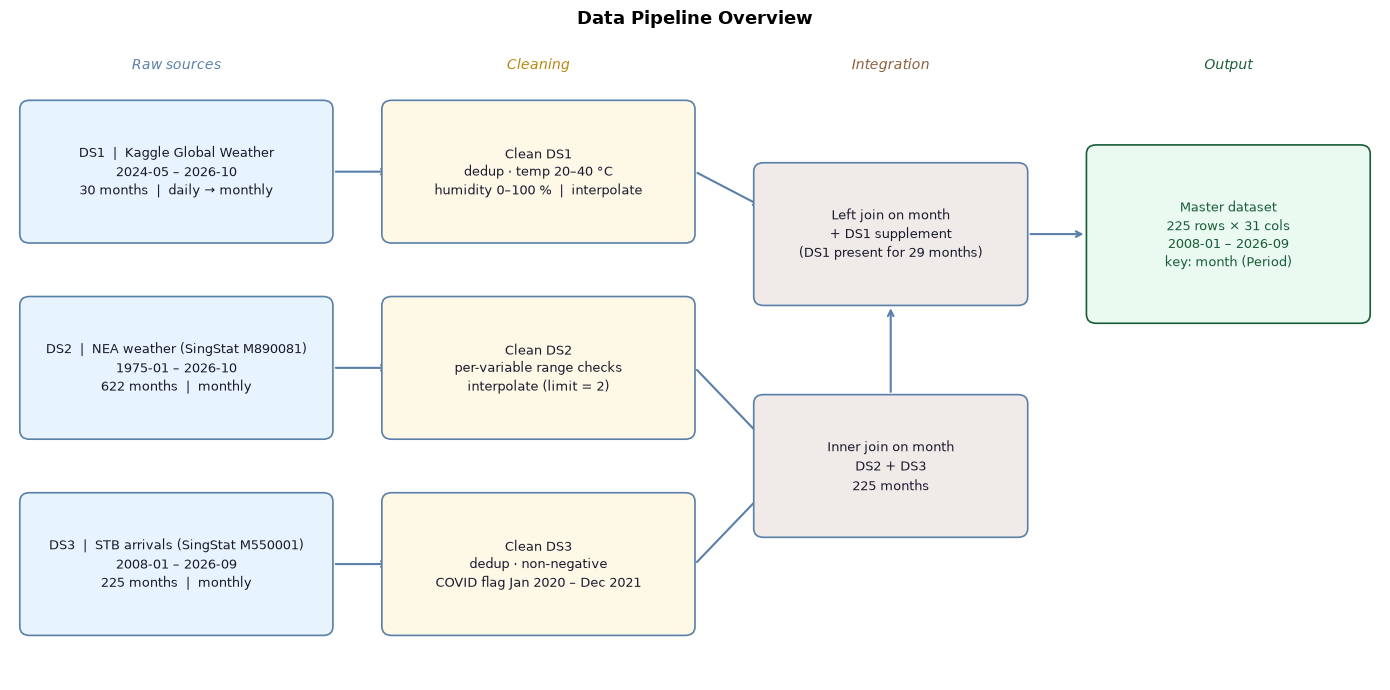

In [17]:
def span(d):
    return f"{d['month'].min()} – {d['month'].max()}"

fig, ax = plt.subplots(figsize=(14, 7))
ax.set_xlim(0, 14)
ax.set_ylim(0, 7.2)
ax.axis("off")

def box(x, y, w, h, label, face, edge="#5a7fa8", text="#1a1a2e"):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.1",
                                         linewidth=1.2, edgecolor=edge, facecolor=face, zorder=2))
    ax.text(x + w / 2, y + h / 2, label, ha="center", va="center", fontsize=9,
            color=text, zorder=3, multialignment="center", linespacing=1.5)

def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="#5a7fa8", lw=1.5), zorder=1)

SRC, CLEAN, JOIN, OUT = "#e8f4fd", "#fef9e7", "#f0ebe8", "#eafaf1"
rows = {'DS1': 5.0, 'DS2': 2.8, 'DS3': 0.6}   # box bottoms; height 1.4

box(0.2, rows['DS1'], 3.0, 1.4, f"DS1  |  Kaggle Global Weather\n{span(ds1)}\n{len(ds1)} months  |  daily → monthly", SRC)
box(0.2, rows['DS2'], 3.0, 1.4, f"DS2  |  NEA weather (SingStat M890081)\n{span(ds2)}\n{len(ds2)} months  |  monthly", SRC)
box(0.2, rows['DS3'], 3.0, 1.4, f"DS3  |  STB arrivals (SingStat M550001)\n{span(ds3)}\n{len(ds3)} months  |  monthly", SRC)

box(3.9, rows['DS1'], 3.0, 1.4, "Clean DS1\ndedup · temp 20–40 °C\nhumidity 0–100 %  |  interpolate", CLEAN)
box(3.9, rows['DS2'], 3.0, 1.4, "Clean DS2\nper-variable range checks\ninterpolate (limit = 2)", CLEAN)
box(3.9, rows['DS3'], 3.0, 1.4, "Clean DS3\ndedup · non-negative\nCOVID flag Jan 2020 – Dec 2021", CLEAN)

n_inner = len(pd.merge(ds2[['month']], ds3[['month']], on='month'))
box(7.7, 1.7, 2.6, 1.4, f"Inner join on month\nDS2 + DS3\n{n_inner} months", JOIN)
box(7.7, 4.3, 2.6, 1.4, f"Left join on month\n+ DS1 supplement\n(DS1 present for {df_master['ds1_temp_celsius'].notna().sum()} months)", JOIN)
box(11.1, 4.1, 2.7, 1.8, f"Master dataset\n{df_master.shape[0]} rows × {df_master.shape[1]} cols\n{span(df_master)}\nkey: month (Period)",
    OUT, edge="#1a5c38", text="#1a5c38")

for r in rows.values():
    arrow(3.3, r + 0.7, 3.9, r + 0.7)                     # source -> cleaning
arrow(7.0, rows['DS2'] + 0.7, 7.7, 2.7)                   # DS2 -> inner join
arrow(7.0, rows['DS3'] + 0.7, 7.7, 2.1)                   # DS3 -> inner join
arrow(9.0, 3.2, 9.0, 4.2)                                 # inner -> left join
arrow(7.0, rows['DS1'] + 0.7, 7.7, 5.3)                   # DS1 -> left join
arrow(10.4, 5.0, 11.0, 5.0)                               # left join -> master

for x, label, color in [(1.7, "Raw sources", "#5a7fa8"), (5.4, "Cleaning", "#b7860b"),
                        (9.0, "Integration", "#8b5e3c"), (12.45, "Output", "#1a5c38")]:
    ax.text(x, 6.85, label, ha="center", fontsize=10, color=color, fontstyle="italic")

ax.set_title("Data Pipeline Overview", fontsize=13, fontweight="bold", pad=10)
plt.tight_layout()
plt.show()

#### 2.4.2 Cross-check of DS1 against DS2

Overlapping months: 29  (2024-05 to 2026-09)

  Temperature  (DS1 avg reading vs DS2 mean daily max)       r = +0.42  (p = 0.025)
  Humidity     (DS1 avg reading vs DS2 24h mean)             r = +0.05  (p = 0.802)
  Rainfall     (DS1 avg daily precip vs DS2 monthly total)   r = +0.73  (p = 0.000)


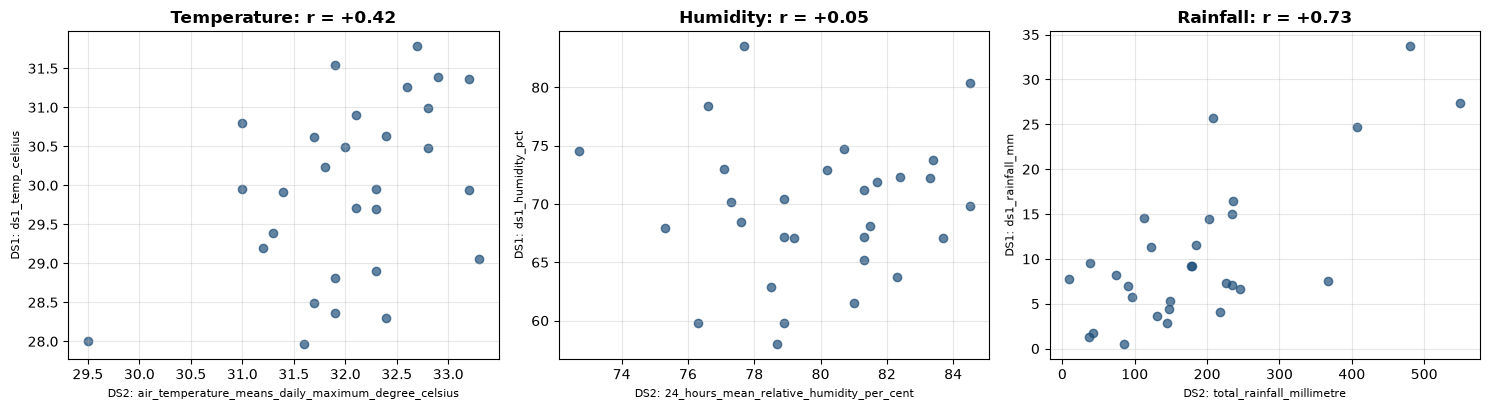

In [18]:
# DS1 (Kaggle) and DS2 (NEA) both measure Singapore weather, so where they overlap they should agree.
overlap = df_master.dropna(subset=['ds1_temp_celsius'])
pairs = [
    ('ds1_temp_celsius', 'air_temperature_means_daily_maximum_degree_celsius', 'Temperature  (DS1 avg reading vs DS2 mean daily max)'),
    ('ds1_humidity_pct', '24_hours_mean_relative_humidity_per_cent',          'Humidity     (DS1 avg reading vs DS2 24h mean)'),
    ('ds1_rainfall_mm',  'total_rainfall_millimetre',                         'Rainfall     (DS1 avg daily precip vs DS2 monthly total)'),
]
print(f"Overlapping months: {len(overlap)}  ({overlap['month'].min()} to {overlap['month'].max()})\n")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (c1, c2, label) in zip(axes, pairs):
    r, p = stats.pearsonr(overlap[c1], overlap[c2])
    print(f"  {label:<58} r = {r:+.2f}  (p = {p:.3f})")
    ax.scatter(overlap[c2], overlap[c1], color='#1f4e79', alpha=0.7)
    ax.set_xlabel(f"DS2: {c2}", fontsize=8)
    ax.set_ylabel(f"DS1: {c1}", fontsize=8)
    ax.set_title(f"{label.split('(')[0].strip()}: r = {r:+.2f}", fontweight='bold')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

DS1 and DS2 overlap for 29 months, which lets us check whether the two weather sources agree:

- **Rainfall agrees strongly (r = +0.73).** Months that are wet in the NEA data are also wet in the Kaggle data.
- **Temperature agrees moderately (r = +0.42).** DS1 is built from one "current weather" reading per day, while DS2 reports the mean daily maximum, so only partial agreement is expected.
- **Humidity does not agree (r = +0.05).** A single daily reading, taken at varying times of day, does not capture the 24-hour mean that DS2 reports.

This supports using **DS2 as the weather source for the analysis**: it is the official NEA record, it covers the whole 2008–2026 period, and DS1 reproduces it only partly. With just 29 months, these correlations are rough indications only.

## 3. Analyse the Data (Analyse)

This section asks whether weather explains how many tourists visit Singapore each month. It has two parts:

- **3.1 Descriptive:** what the arrivals and weather data look like.
- **3.2 Diagnostic:** whether weather and arrivals move together.

Two definitions are used throughout:

- **Seasonal index.** Arrivals grew from about 10 million a year in 2008 to 19 million in 2019, so raw monthly numbers mostly show that growth. Dividing each month's arrivals by the average month of the same year removes the trend. An index of 1.10 means the month was 10% busier than a typical month that year.
- **Stable years.** The seasonal index is only fair for complete years without a steep trend inside the year. So 2020–2021 (COVID), 2022–2023 (reopening and recovery) and 2026 (only January–September available) are left out. That leaves 14 years: 2008–2019, 2024 and 2025.

In [19]:
# ── Shared definitions for Section 3 ──
TARGET = 'tourist_arrivals'

WEATHER_COLS = [
    'total_rainfall_millimetre',
    'number_of_rainy_days_number',
    'bright_sunshine_daily_mean_hour',
    'air_temperature_means_daily_maximum_degree_celsius',
    '24_hours_mean_relative_humidity_per_cent',
]
SHORT = {
    'total_rainfall_millimetre': 'Rainfall',
    'number_of_rainy_days_number': 'Rainy Days',
    'bright_sunshine_daily_mean_hour': 'Sunshine',
    'air_temperature_means_daily_maximum_degree_celsius': 'Max Temp',
    'air_temperature_means_daily_minimum_degree_celsius': 'Min Temp',
    '24_hours_mean_relative_humidity_per_cent': 'Humidity',
    'tourist_arrivals': 'Arrivals',
    'arrivals_index': 'Seasonal Index',
}
MONTH_LBL = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
SEASON_ORDER = ['Northeast Monsoon', 'Inter-monsoon 1', 'Southwest Monsoon', 'Inter-monsoon 2']
SEASON_COLORS = dict(zip(SEASON_ORDER, ['#2b6cb0', '#68a063', '#d69e2e', '#a05195']))
COVID_YEARS = [2020, 2021]
RECOVERY_YEARS = [2022, 2023]   # reopening and recovery: arrivals rose steadily through these years
millions = mticker.FuncFormatter(lambda v, _: f"{v / 1e6:.1f}M")

df = df_master.copy()
df['date'] = df['month'].dt.to_timestamp()

# Seasonal index: a month's arrivals relative to the average month of the same year.
# It removes the long-run growth trend, so months can be compared across years.
df['arrivals_index'] = df[TARGET] / df.groupby('year')[TARGET].transform('mean')

# "Stable" years: complete calendar years outside COVID and the recovery years.
# Only these give a fair seasonal index (a partial year, or one with a steep trend, distorts the yearly average).
complete_year = df.groupby('year')['month'].transform('size') == 12
df['stable_year'] = complete_year & ~df['year'].isin(COVID_YEARS + RECOVERY_YEARS)

# Each calendar month's monsoon season (fixed in the enrichment step)
MONTH_SEASON = df.groupby('month_num')['season'].agg(lambda s: s.mode()[0])

print(f"Master data : {df['month'].min()} to {df['month'].max()}  ({len(df)} months)")
stable_years = sorted(int(y) for y in df.loc[df['stable_year'], 'year'].unique())
print(f"Stable years: {stable_years[0]}–{stable_years[-1]} except {[y for y in range(stable_years[0], stable_years[-1] + 1) if y not in stable_years]}  ({df['stable_year'].sum()} months)")

Master data : 2008-01 to 2026-09  (225 months)
Stable years: 2008–2025 except [2020, 2021, 2022, 2023]  (168 months)


### 3.1 Descriptive Analysis

This part summarises the variables and shows the long-run trend in arrivals. It then shows the seasonal pattern of arrivals and the seasonal pattern of the weather.

#### 3.1.1 Variable Summary

In [20]:
summary = df[WEATHER_COLS + [TARGET]].rename(columns=SHORT).describe().T
summary['cv_%'] = summary['std'] / summary['mean'] * 100   # coefficient of variation: spread relative to the mean
print("Summary of the analysis variables (all months)\n")
print(summary[['count', 'mean', 'std', 'min', '50%', 'max', 'cv_%']].round(2).to_string())

Summary of the analysis variables (all months)

            count        mean        std    min        50%        max   cv_%
Rainfall    225.0      174.70     105.26    0.2      161.0      692.8  60.25
Rainy Days  225.0       14.66       5.31    1.0       15.0       27.0  36.25
Sunshine    225.0        5.79       1.18    3.3        5.8        9.2  20.41
Max Temp    225.0       31.68       0.84   29.1       31.7       33.5   2.64
Humidity    225.0       79.99       3.68   72.0       79.8       88.4   4.59
Arrivals    225.0  1091228.79  456517.32  750.0  1208624.0  1802593.0  41.84


- **Arrivals vary far more than the weather** (coefficient of variation, CV, 42%). Most of that comes from long-run growth and the COVID collapse.
- **Rainfall is the most variable weather measure** (CV 60%), ranging from 0.2 mm to 693 mm in a month.
- **Temperature and humidity barely change** (CV 2.6% and 4.6%). The mean daily maximum temperature stays between 29.1 °C and 33.5 °C.

So if weather does affect arrivals, rainfall and sunshine are the likely channels, because temperature and humidity hardly vary.

#### 3.1.2 Tourist Arrivals Over Time

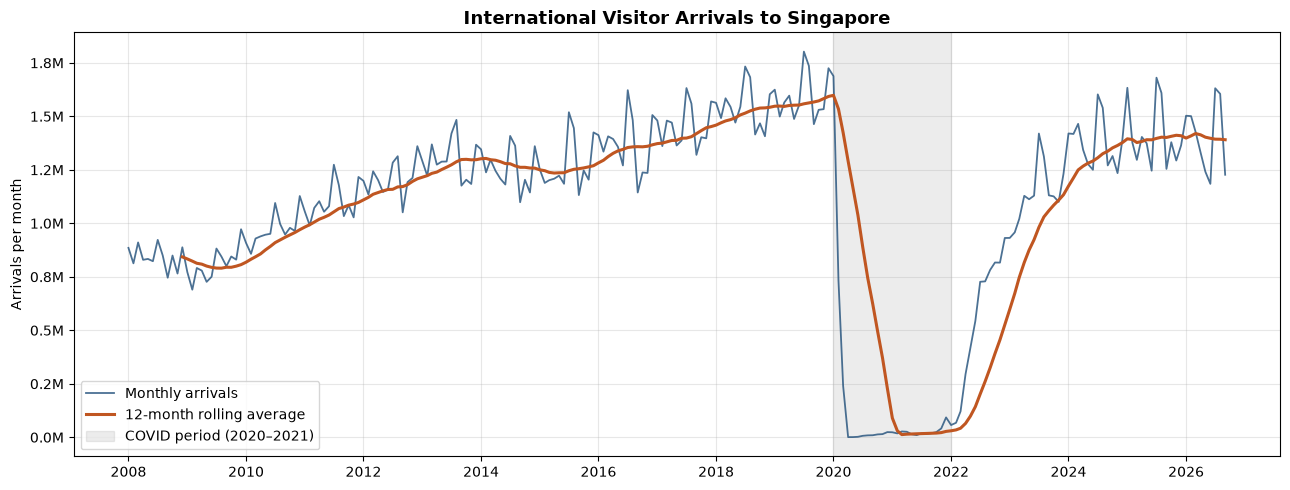

Highest pre-COVID month : 2019-07  1,802,593
Lowest month (COVID)    : 2020-04  750

Annual totals (millions):
year         2008   2009   2010   2011  2012   2013  2014   2015  2016   2017   2018   2019   2020   2021   2022  2023   2024   2025   2026
arrivals_M  10.12   9.68  11.64  13.17  14.5  15.57  15.1  15.23  16.4  17.42  18.51  19.12   2.74   0.33   6.31  13.6  16.53  16.91  12.65
months      12.00  12.00  12.00  12.00  12.0  12.00  12.0  12.00  12.0  12.00  12.00  12.00  12.00  12.00  12.00  12.0  12.00  12.00   9.00


In [21]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df['date'], df[TARGET], color='#1f4e79', lw=1.3, alpha=0.8, label='Monthly arrivals')
ax.plot(df['date'], df[TARGET].rolling(12).mean(), color='#c05621', lw=2.2, label='12-month rolling average')
covid = df[df['covid_period'] == 1]
ax.axvspan(covid['date'].min(), covid['date'].max() + pd.offsets.MonthEnd(0),
           color='grey', alpha=0.15, label='COVID period (2020–2021)')
ax.yaxis.set_major_formatter(millions)
ax.set_title("International Visitor Arrivals to Singapore", fontsize=13, fontweight='bold')
ax.set_ylabel("Arrivals per month")
ax.legend(loc='lower left')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

annual = df.groupby('year').agg(total=(TARGET, 'sum'), months=(TARGET, 'size'))
pre_covid_peak = df[df['year'] < 2020].loc[lambda d: d[TARGET].idxmax()]
trough = df.loc[df[TARGET].idxmin()]
print(f"Highest pre-COVID month : {pre_covid_peak['month']}  {pre_covid_peak[TARGET]:,.0f}")
print(f"Lowest month (COVID)    : {trough['month']}  {trough[TARGET]:,.0f}")
print("\nAnnual totals (millions):")
print((annual['total'] / 1e6).round(2).to_frame('arrivals_M').join(annual['months']).T.to_string())

- **2008–2019, steady growth.** Annual arrivals almost doubled, from 10.1M to 19.1M. The busiest pre-COVID month was July 2019 (1.80M).
- **2020–2021, collapse.** Borders closed in 2020, and April 2020 had only 750 arrivals. 2021 had 0.33M arrivals in the whole year.
- **2022 onwards, recovery.** Annual arrivals were 6.3M in 2022, 13.6M in 2023 and 16.5M in 2024. The 2025 total (16.9M) is still about 12% below 2019. January to September 2026 adds up to 12.7M.

The long-run trend and the COVID shock are much larger than any month-to-month weather effect could be. This is why the following sections use the seasonal index and leave out 2020–2023.

#### 3.1.3 Seasonal Pattern of Arrivals

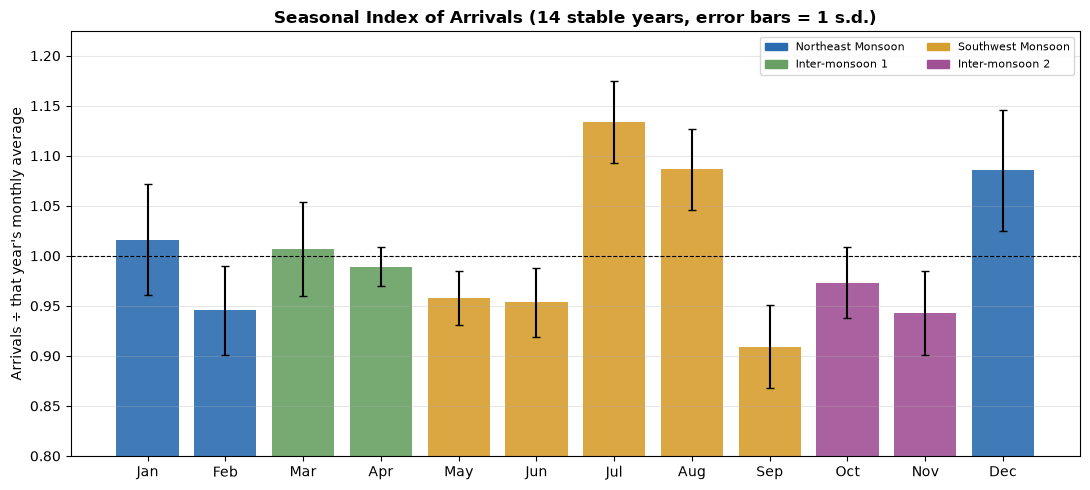

     index  index_sd avg_arrivals
Jan  1.016     0.055    1,274,614
Feb  0.945     0.044    1,186,849
Mar  1.007     0.047    1,257,948
Apr  0.989     0.019    1,238,110
May  0.958     0.027    1,197,023
Jun  0.953     0.034    1,190,587
Jul  1.134     0.041    1,419,850
Aug  1.086     0.041    1,363,195
Sep  0.909     0.041    1,132,325
Oct  0.973     0.036    1,209,762
Nov  0.943     0.042    1,173,813
Dec  1.085     0.061    1,348,332


In [22]:
stable = df[df['stable_year']]
seasonal = stable.groupby('month_num')['arrivals_index'].agg(['mean', 'std'])
seasonal['avg_arrivals'] = stable.groupby('month_num')[TARGET].mean()

fig, ax = plt.subplots(figsize=(11, 5))
colors = [SEASON_COLORS[MONTH_SEASON[m]] for m in seasonal.index]
ax.bar(seasonal.index, seasonal['mean'], yerr=seasonal['std'], color=colors, capsize=3, alpha=0.9)
ax.axhline(1, color='black', lw=0.8, ls='--')
ax.set_ylim(0.8, seasonal['mean'].max() + seasonal['std'].max() + 0.03)
ax.set_xticks(range(1, 13), MONTH_LBL)
ax.set_ylabel("Arrivals ÷ that year's monthly average")
ax.set_title(f"Seasonal Index of Arrivals ({len(stable['year'].unique())} stable years, error bars = 1 s.d.)",
             fontsize=12, fontweight='bold')
ax.legend(handles=[mpatches.Patch(color=c, label=s) for s, c in SEASON_COLORS.items()], fontsize=8, ncol=2)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

out = seasonal.rename(columns={'mean': 'index', 'std': 'index_sd'}).round(3)
out.index = MONTH_LBL
print(out.to_string(formatters={'avg_arrivals': '{:,.0f}'.format}))

The seasonal pattern is very consistent from year to year (the standard deviations are only 2–6 percentage points):

- **Peaks: July (+13%), August (+9%) and December (+9%).** These match the school holidays in Singapore's main source markets: the Northern-hemisphere summer and the year-end break.
- **Quiet months: September (−9%), November and February (about −6%), May and June (about −5%).**

The busy months are not the months with the best weather. December is the wettest month of the year (see 3.1.4), yet it is one of the busiest. February is the sunniest and driest, yet it is one of the quietest. This first look already suggests that holidays, not weather, set the seasonal pattern.

#### 3.1.4 Monthly Weather Profile

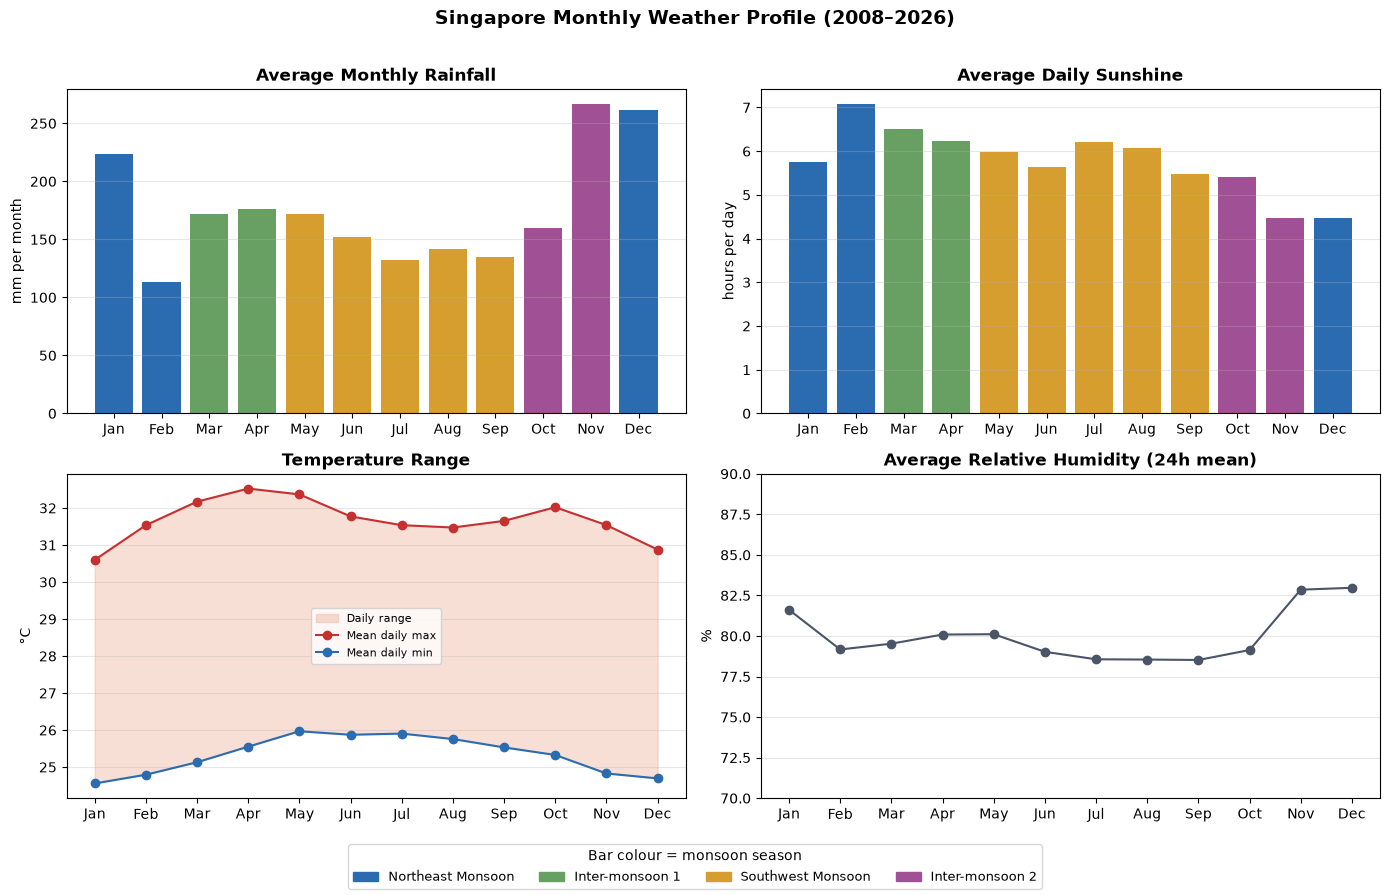

     Rainfall  Rainy Days  Sunshine  Max Temp  Humidity
Jan     223.9        13.7       5.8      30.6      81.6
Feb     113.2         9.0       7.1      31.5      79.2
Mar     172.0        12.3       6.5      32.2      79.5
Apr     176.1        15.5       6.2      32.5      80.1
May     171.4        15.5       6.0      32.4      80.1
Jun     152.1        13.9       5.6      31.8      79.0
Jul     132.6        13.6       6.2      31.5      78.6
Aug     141.6        14.0       6.1      31.5      78.5
Sep     134.9        13.3       5.5      31.7      78.5
Oct     159.6        15.8       5.4      32.0      79.1
Nov     266.3        21.2       4.5      31.5      82.9
Dec     261.3        18.9       4.5      30.9      83.0


In [23]:
clim = df.groupby('month_num')[WEATHER_COLS + ['air_temperature_means_daily_minimum_degree_celsius']].mean()
x = clim.index
colors = [SEASON_COLORS[MONTH_SEASON[m]] for m in x]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

ax = axes[0, 0]
ax.bar(x, clim['total_rainfall_millimetre'], color=colors)
ax.set_title("Average Monthly Rainfall", fontweight='bold'); ax.set_ylabel("mm per month")

ax = axes[0, 1]
ax.bar(x, clim['bright_sunshine_daily_mean_hour'], color=colors)
ax.set_title("Average Daily Sunshine", fontweight='bold'); ax.set_ylabel("hours per day")

ax = axes[1, 0]
tmin = clim['air_temperature_means_daily_minimum_degree_celsius']
tmax = clim['air_temperature_means_daily_maximum_degree_celsius']
ax.fill_between(x, tmin, tmax, color='#e9967a', alpha=0.3, label='Daily range')
ax.plot(x, tmax, marker='o', color='#c53030', label='Mean daily max')
ax.plot(x, tmin, marker='o', color='#2b6cb0', label='Mean daily min')
ax.set_title("Temperature Range", fontweight='bold'); ax.set_ylabel("°C"); ax.legend(fontsize=8)

ax = axes[1, 1]
ax.plot(x, clim['24_hours_mean_relative_humidity_per_cent'], marker='o', color='#4a5568')
ax.set_ylim(70, 90)
ax.set_title("Average Relative Humidity (24h mean)", fontweight='bold'); ax.set_ylabel("%")

for ax in axes.flat:
    ax.set_xticks(range(1, 13), MONTH_LBL)
    ax.grid(axis='y', alpha=0.3)
fig.legend(handles=[mpatches.Patch(color=c, label=s) for s, c in SEASON_COLORS.items()],
           loc='lower center', ncol=4, fontsize=9, title='Bar colour = monsoon season')
fig.suptitle(f"Singapore Monthly Weather Profile ({df['year'].min()}–{df['year'].max()})", fontsize=14, fontweight='bold')
plt.tight_layout(rect=(0, 0.06, 1, 0.97))
plt.show()

out = clim[WEATHER_COLS].rename(columns=SHORT).round(1)
out.index = MONTH_LBL
print(out.to_string())

- **Rainfall** follows the monsoons. November and December are the wettest months (about 265 mm each, the start of the Northeast Monsoon), and February is the driest (113 mm).
- **Sunshine** mirrors rainfall. It is highest in February (7.1 hours a day) and lowest in November and December (4.5 hours a day).
- **Temperature** moves by only about 2 °C over the year. The mean daily maximum peaks in April (32.5 °C) and is lowest in January (30.6 °C).
- **Humidity** stays between about 78% and 83%, rising slightly in the wet November–January months.

Rainfall and sunshine have a clear yearly cycle. Temperature and humidity are almost constant, so they cannot account for the arrival peaks in 3.1.3.

### 3.2 Diagnostic Analysis

This part tests whether weather and arrivals move together, using the 168 months of the stable years. Each weather variable is compared with arrivals in three ways, from the weakest test to the strongest:

1. **Raw arrivals.** The simplest comparison, but it can mislead: arrivals grew over time, so any weather variable that also drifted over time will appear correlated with them.
2. **Seasonal index.** Removes the growth trend. It asks whether wetter or sunnier calendar months tend to be busier.
3. **Anomalies.** For both the weather and the seasonal index, subtract the usual value for that calendar month. This asks: when a month is wetter than usual (for example an unusually rainy July), does it get fewer tourists than a usual July? Because the holiday calendar is removed, this is the closest this data comes to testing whether the weather itself changes arrivals.

The p-values assume that months are independent of one another. Neighbouring months are not fully independent, so p-values close to 0.05 should be read with caution.

In [24]:
df_clean = df[df['stable_year']].copy()

# Anomalies: how unusual a month was compared with the same calendar month in other years
for c in WEATHER_COLS + ['arrivals_index']:
    df_clean[c + '_anom'] = df_clean[c] - df_clean.groupby('month_num')[c].transform('mean')

print(f"Months used for diagnostics: {len(df_clean)}  "
      f"({df_clean['month'].min()} to {df_clean['month'].max()}, "
      f"excluding {COVID_YEARS + RECOVERY_YEARS} and incomplete years)")

Months used for diagnostics: 168  (2008-01 to 2025-12, excluding [2020, 2021, 2022, 2023] and incomplete years)


#### 3.2.1 Correlation Heatmap

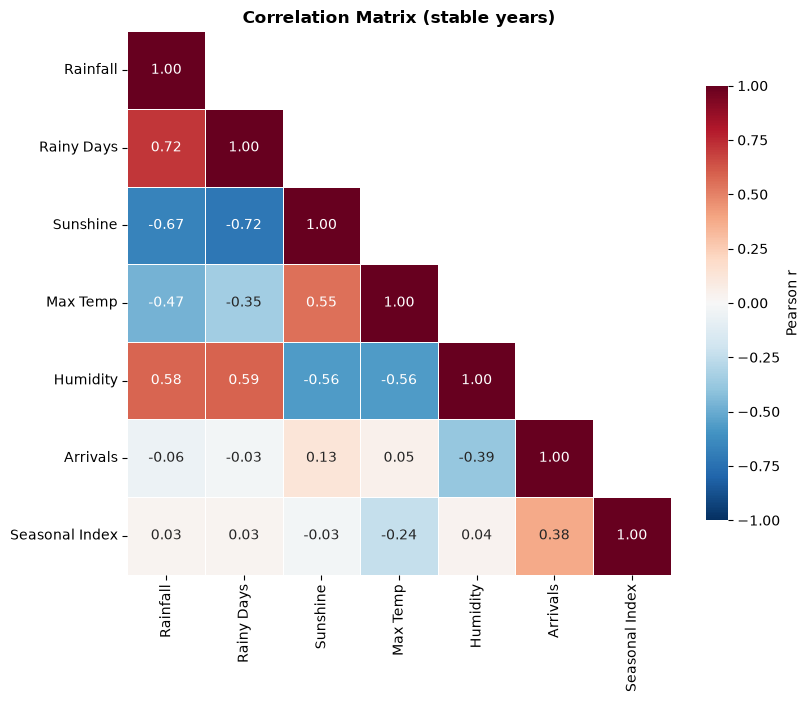

In [25]:
cols = WEATHER_COLS + [TARGET, 'arrivals_index']
corr_mat = df_clean[cols].rename(columns=SHORT).corr()

fig, ax = plt.subplots(figsize=(8.5, 7))
mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)
sns.heatmap(corr_mat, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8, 'label': 'Pearson r'}, ax=ax)
ax.set_title("Correlation Matrix (stable years)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

- **The weather variables are strongly linked to each other.** Rainfall and rainy days move together (r = 0.72), and both move opposite to sunshine (r = −0.67 and −0.72). Humidity rises with rain and falls with sunshine and heat.
- **Their links to tourism are weak.** In the bottom two rows, every correlation is between −0.39 and +0.13. The two largest, humidity with raw arrivals (−0.39) and max temperature with the seasonal index (−0.24), are explained in 3.2.2.

#### 3.2.2 Per-Variable Correlation with Tourist Arrivals

n = 168 months

            r_raw_arrivals  p_raw  r_seasonal_index  p_index  spearman_index  r_anomalies  p_anom
variable                                                                                         
Rainfall            -0.060  0.439             0.030    0.704           0.041       -0.062   0.426
Rainy Days          -0.031  0.693             0.030    0.700           0.041       -0.007   0.925
Sunshine             0.129  0.095            -0.025    0.747           0.005       -0.060   0.441
Max Temp             0.050  0.518            -0.242    0.002          -0.216       -0.078   0.316
Humidity            -0.390  0.000             0.038    0.626           0.066        0.055   0.477


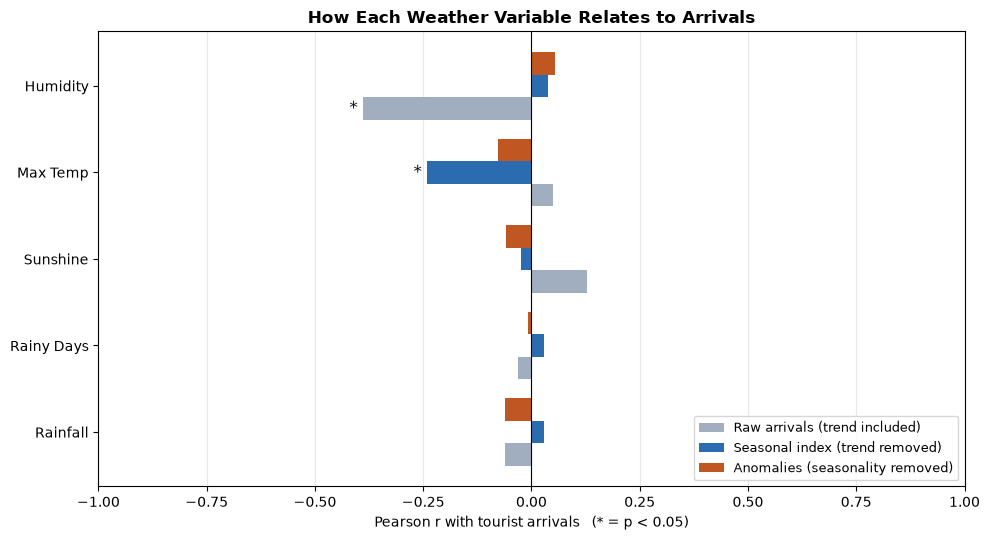

In [26]:
rows = []
for c in WEATHER_COLS:
    r_raw, p_raw = stats.pearsonr(df_clean[c], df_clean[TARGET])
    r_idx, p_idx = stats.pearsonr(df_clean[c], df_clean['arrivals_index'])
    rho_idx, _ = stats.spearmanr(df_clean[c], df_clean['arrivals_index'])
    r_an, p_an = stats.pearsonr(df_clean[c + '_anom'], df_clean['arrivals_index_anom'])
    rows.append({'variable': SHORT[c],
                 'r_raw_arrivals': r_raw, 'p_raw': p_raw,
                 'r_seasonal_index': r_idx, 'p_index': p_idx, 'spearman_index': rho_idx,
                 'r_anomalies': r_an, 'p_anom': p_an})
corr_tbl = pd.DataFrame(rows).set_index('variable')
print(f"n = {len(df_clean)} months\n")
print(corr_tbl.round(3).to_string())

measures = [('r_raw_arrivals', 'p_raw', 'Raw arrivals (trend included)', '#a0aec0'),
            ('r_seasonal_index', 'p_index', 'Seasonal index (trend removed)', '#2b6cb0'),
            ('r_anomalies', 'p_anom', 'Anomalies (seasonality removed)', '#c05621')]
fig, ax = plt.subplots(figsize=(10, 5.5))
y = np.arange(len(corr_tbl))
h = 0.26
for k, (rc, pc, label, color) in enumerate(measures):
    pos = y + (k - 1) * h
    ax.barh(pos, corr_tbl[rc], height=h, color=color, label=label)
    for yy, (r, p) in zip(pos, corr_tbl[[rc, pc]].values):
        if p < 0.05:
            ax.text(r + (0.01 if r >= 0 else -0.01), yy, '*', va='center',
                    ha='left' if r >= 0 else 'right', fontsize=12)
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y, corr_tbl.index)
ax.set_xlim(-1, 1)
ax.set_xlabel("Pearson r with tourist arrivals   (* = p < 0.05)")
ax.set_title("How Each Weather Variable Relates to Arrivals", fontsize=12, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

- **Raw arrivals: only humidity is significant (r = −0.39), and that is a trend effect.** Average humidity fell over the period (about 83% in 2008–2012 and about 77–81% in later years) while arrivals grew. Once the trend is removed, the correlation drops to +0.04.
- **Seasonal index: only max temperature is significant (r = −0.24, p = 0.002).** The hottest calendar months (April–May) are slightly quieter, and the coolest (December–January) are busier. But the anomaly test gives r = −0.08 (p = 0.32): an unusually hot month does not get fewer tourists than usual. The link comes from the calendar, because the hottest months fall outside the main holidays, not from heat putting tourists off.
- **Anomalies: no weather variable is significant** (all |r| ≤ 0.08, all p > 0.3). Months that are unusually wet, sunny, hot or humid get the usual number of tourists.

**Conclusion:** the data shows no sign that weather drives monthly tourist arrivals. The only correlations found come from the growth trend or the holiday calendar.

#### 3.2.3 Variables vs Tourist Arrivals

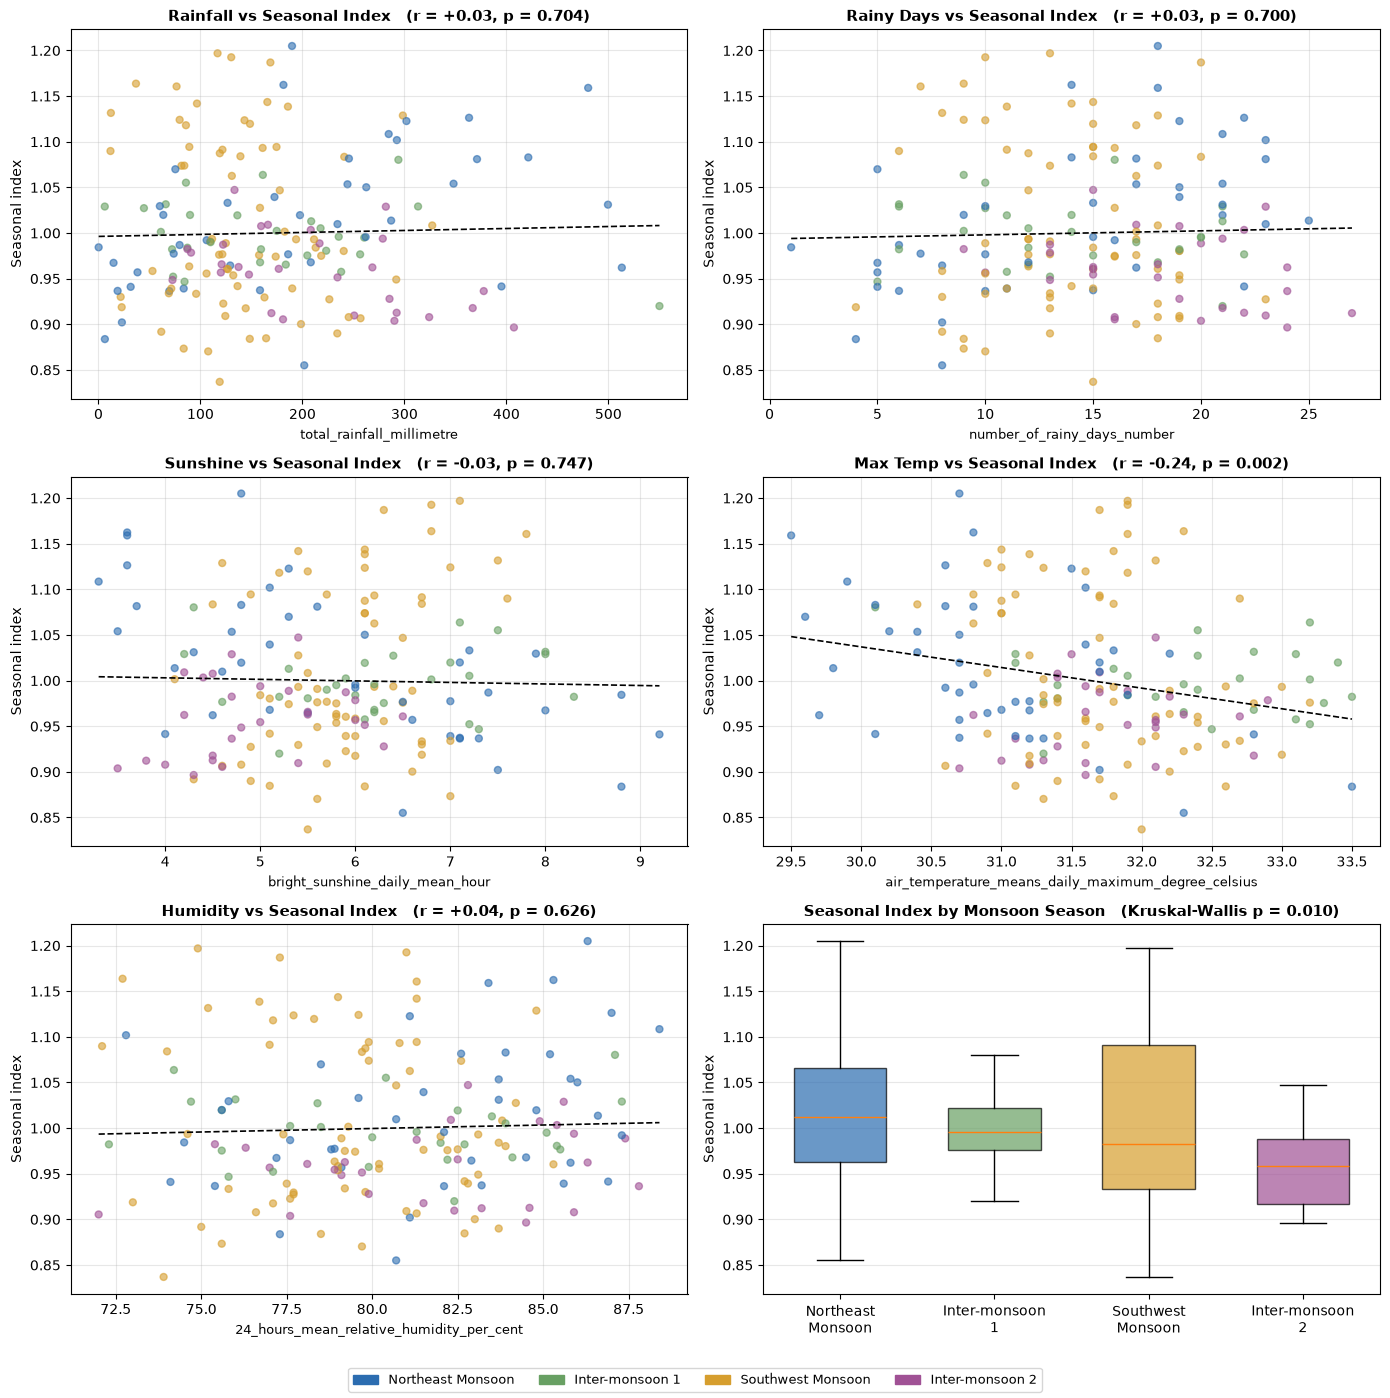

In [27]:
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
point_colors = df_clean['season'].map(SEASON_COLORS)

for ax, c in zip(axes.flat, WEATHER_COLS):
    xv, yv = df_clean[c], df_clean['arrivals_index']
    ax.scatter(xv, yv, c=point_colors, alpha=0.6, s=25)
    m, b = np.polyfit(xv, yv, 1)
    xs = np.linspace(xv.min(), xv.max(), 50)
    ax.plot(xs, m * xs + b, color='black', ls='--', lw=1.2)
    r, p = stats.pearsonr(xv, yv)
    ax.set_title(f"{SHORT[c]} vs Seasonal Index   (r = {r:+.2f}, p = {p:.3f})", fontsize=11, fontweight='bold')
    ax.set_xlabel(c, fontsize=9)
    ax.set_ylabel("Seasonal index")
    ax.grid(alpha=0.3)

ax = axes[2, 1]
data = [df_clean.loc[df_clean['season'] == s, 'arrivals_index'] for s in SEASON_ORDER]
bp = ax.boxplot(data, patch_artist=True, widths=0.6)
for patch, s in zip(bp['boxes'], SEASON_ORDER):
    patch.set_facecolor(SEASON_COLORS[s]); patch.set_alpha(0.7)
ax.set_xticks(range(1, 5), [s.replace(' ', '\n', 1) for s in SEASON_ORDER])
h_stat, p_kw = stats.kruskal(*data)
ax.set_title(f"Seasonal Index by Monsoon Season   (Kruskal-Wallis p = {p_kw:.3f})", fontsize=11, fontweight='bold')
ax.set_ylabel("Seasonal index")
ax.grid(axis='y', alpha=0.3)

fig.legend(handles=[mpatches.Patch(color=c, label=s) for s, c in SEASON_COLORS.items()],
           loc='lower center', ncol=4, fontsize=9)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

The scatter plots show the same result: shapeless point clouds with nearly flat trend lines for every weather variable. The only visible slope is for max temperature, which 3.2.2 showed is a calendar effect.

The boxplot does show a difference between monsoon seasons (Kruskal–Wallis p = 0.010). The Inter-monsoon 2 period (October–November) has the lowest median. The Southwest Monsoon (May–September) has the widest spread, because it contains both the July–August peak and the September low. These differences follow from which holidays fall in each season, since none of the weather variables explains them.